# Setup

In [1]:
# Libs
import phobos
import numpy as np
import matplotlib.pyplot as plt
import time
import pickle
from tqdm import tqdm
from pathlib import Path

✅ BMC lib found. Running in control mode.


In [2]:
# Constants
lam = 1551 # [nm]

In [3]:
# shortcuts
dm = phobos.DM()
cam = phobos.Cred3()
inj_seg = phobos.Config().get('injection.segments')
print('Injected segments:', inj_seg)

# Setup
path = phobos.archive.new('kernel_null', verbose=True)


DEBUG - SDK Install Path: /opt/Boston Micromachines
DEBUG - BMC_PCIeOpenDM 27BW007#051 0
DEBUG - 1 BMC PCIe cards installed.
DEBUG - Using automatic devId: 1
DEBUG - BMC_PCIeOpenDM opening 0
INFO - PCIe HW Rev: 20000502
DEBUG - Loading map file: /opt/Boston Micromachines/Map/KILO507.map expected count: 1024
INFO - Loading calibration for DM: 27BW07#051_5_3_setof14
DEBUG - Loading map file: /opt/Boston Micromachines/Map/KILO507.map expected count: 1024
Cred3 camera initialized with dark subtraction
Injected segments: [138, 137, 136, 135]
Archive created at /mnt/disk1/archive/2026-09-15_c64cfaf/1_kernel_null


# Check cropping

✅ Cred3 reset to configuration defaults.


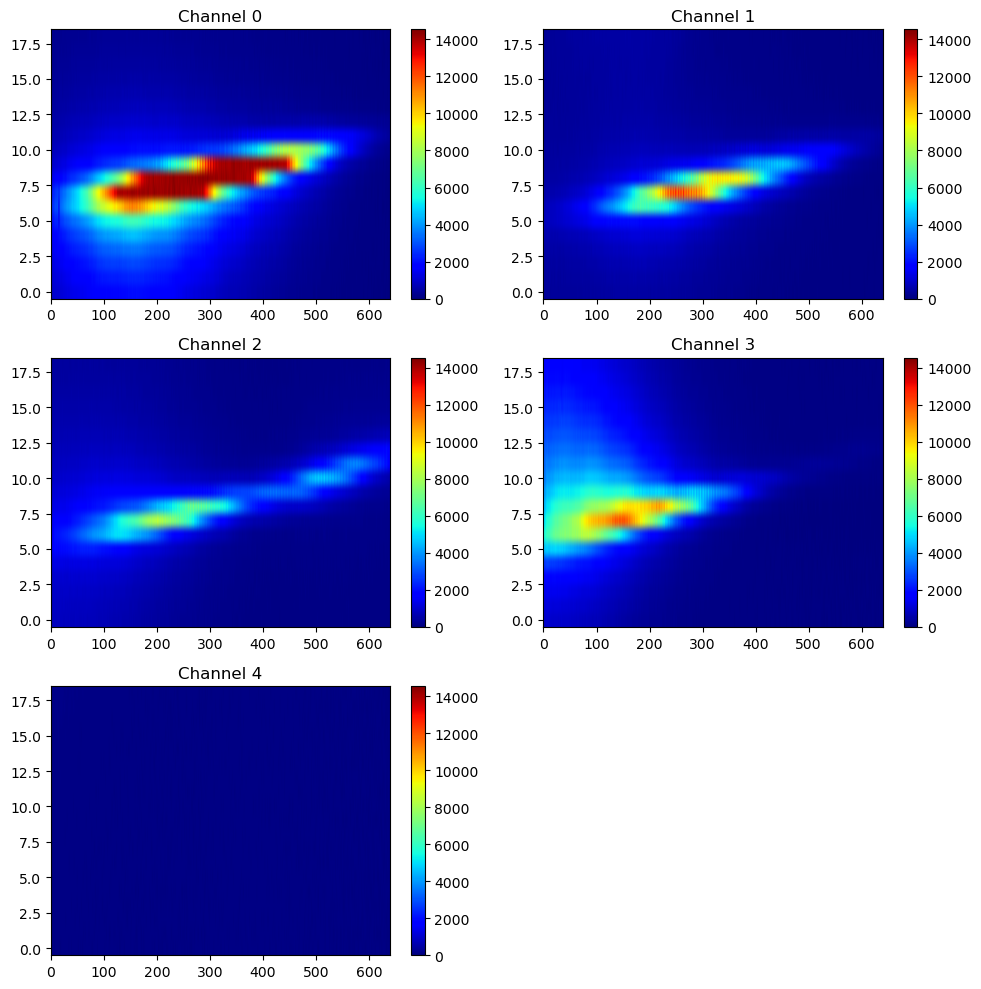

In [9]:
# check cropping
phobos.Config().reload()
cam.reset()
# cam.check_cropping(crop_mode='centers')
cam.check_cropping(crop_mode='rectangles')

# Calibration injection

In [5]:
# Injection calibration
inj = phobos.Injection()


In [ ]:
# inj.zero()
# maps = inj.get_injection_maps(verbose=True)
# inj.zero()

# fig = plt.figure(figsize=(10,10))
# for i in range(4):
#     image = maps[0][i]
#     tip_range = tilt_ramp = maps[1]
#     tilt_step = np.diff(tilt_ramp)[0]
#     tip_step = np.diff(tip_range)[0]
#     plt.subplot(2,2,i+1)
#     plt.imshow(image, origin='lower', cmap='jet',
#             extent=[tilt_ramp.min()-tilt_step/2, tilt_ramp.max()+tilt_step/2,
#                     tip_range.min()-tip_step/2, tip_range.max()+tip_step/2],
#             vmin=maps[0].min(),
#             vmax=maps[0].max())
#     plt.colorbar()
#     plt.xlabel('Tilt (mrad)')
#     plt.ylabel('Tip (mrad)')
# plt.tight_layout()

Scanning injection maps:   0%|          | 0/4 [00:00<?, ?it/s]

  Channel 0 (segment 138): scanning…
Injection OFF on channels [1, 2, 3] (segments [137, 136, 135])


Scanning injection maps:  25%|██▌       | 1/4 [00:17<00:52, 17.62s/it]

Injection OFF on channels [0] (segments [138])
  Channel 1 (segment 137): scanning…
Injection OFF on channels [0, 2, 3] (segments [138, 136, 135])


Scanning injection maps:  50%|█████     | 2/4 [00:36<00:36, 18.34s/it]

...

Scanning injection maps:  75%|███████▌  | 3/4 [00:54<00:18, 18.06s/it]

Injection OFF on channels [2] (segments [136])
  Channel 3 (segment 135): scanning…
Injection OFF on channels [0, 1, 2] (segments [138, 137, 136])


Scanning injection maps: 100%|██████████| 4/4 [01:14<00:00, 18.68s/it]

Injection OFF on channels [3] (segments [135])
Injection FLAT on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])

── Find gross TT for max injection and spread ──
Injection spread of seg=138: (tip, tilt) = (0.69537,0.80287) mrad
Injection spread of seg=137: (tip, tilt) = (0.71688,0.83844) mrad
Injection spread of seg=136: (tip, tilt) = (0.73769,0.83421) mrad
Injection spread of seg=135: (tip, tilt) = (0.72594,0.85299) mrad

── Find precise TT for max injection ──
Injection max of seg=138: (tip, tilt) = (-0.64909,-0.07979) mrad; flux = 462
Injection max of seg=137: (tip, tilt) = (-0.32519,-0.15342) mrad; flux = 366
Injection max of seg=136: (tip, tilt) = (0.06483,-0.26513) mrad; flux = 418.8
Injection max of seg=135: (tip, tilt) = (0.20017,-0.28476) mrad; flux = 581.6
✅ Injection calibration saved to config (injection.max)



── Finding maximum injection points ──

── Balancing injection fluxes ──
  Weakest channel: 1 (seg 137), target flux = 399.2
  Dichotomy on channel 0 (seg 138)…
Injection OFF on channels [1, 2, 3] (segments [137, 136, 135])
    → balanced tilt = 0.6939 mrad, flux = 395.6 (target 399.2), iterations = 13
  Dichotomy on channel 2 (seg 136)…
Injection OFF on channels [0, 1, 3] (segments [138, 137, 135])
    → balanced tilt = 0.3229 mrad, flux = 403.9 (target 399.2), iterations = 13
  Dichotomy on channel 3 (seg 135)…
Injection OFF on channels [0, 1, 2] (segments [138, 137, 136])
    → balanced tilt = 0.4643 mrad, flux = 407.8 (target 399.2), iterations = 13
Injection FLAT on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
✅ Injection calibration saved to config (injection.balanced)


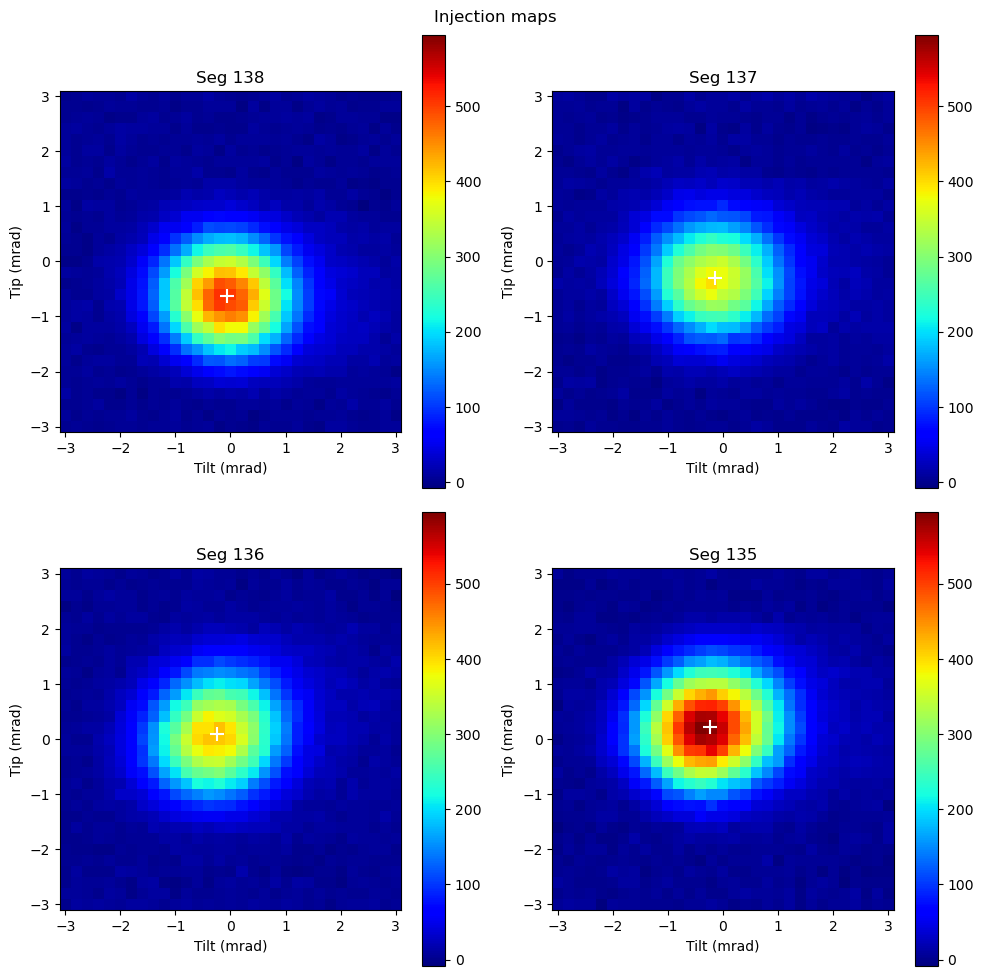

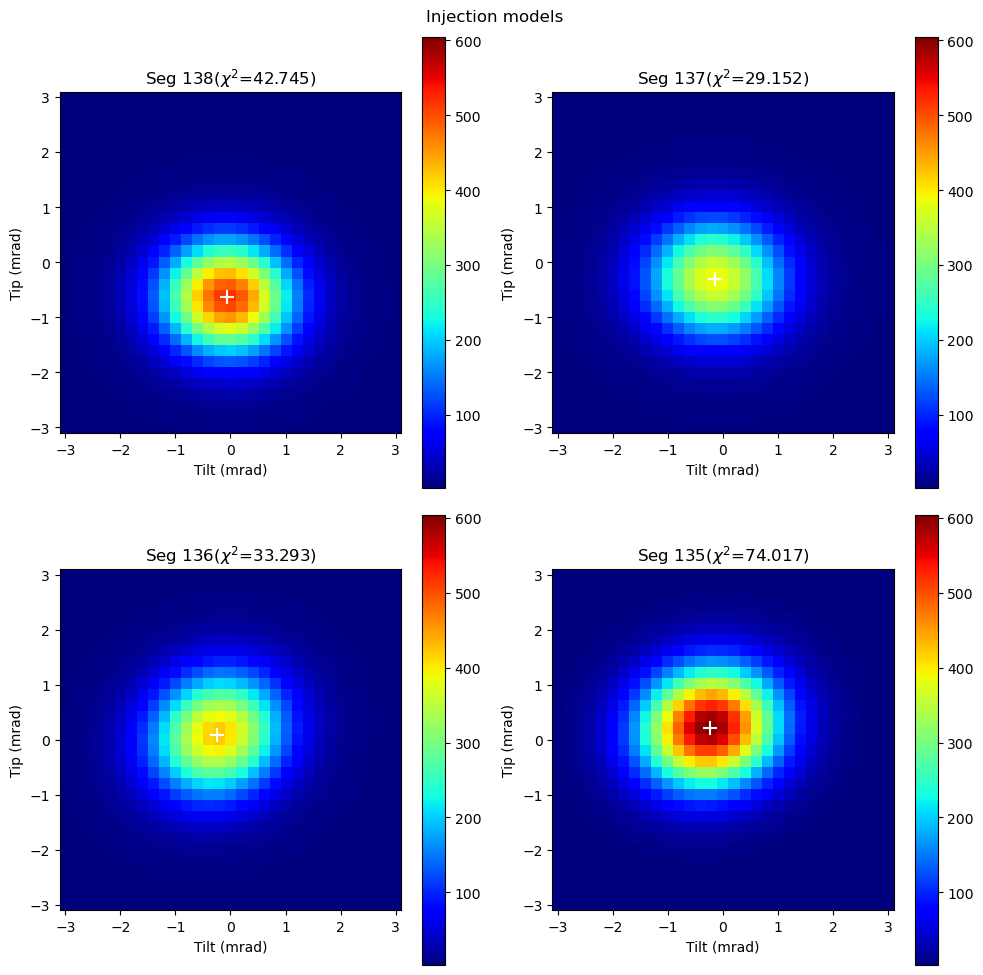

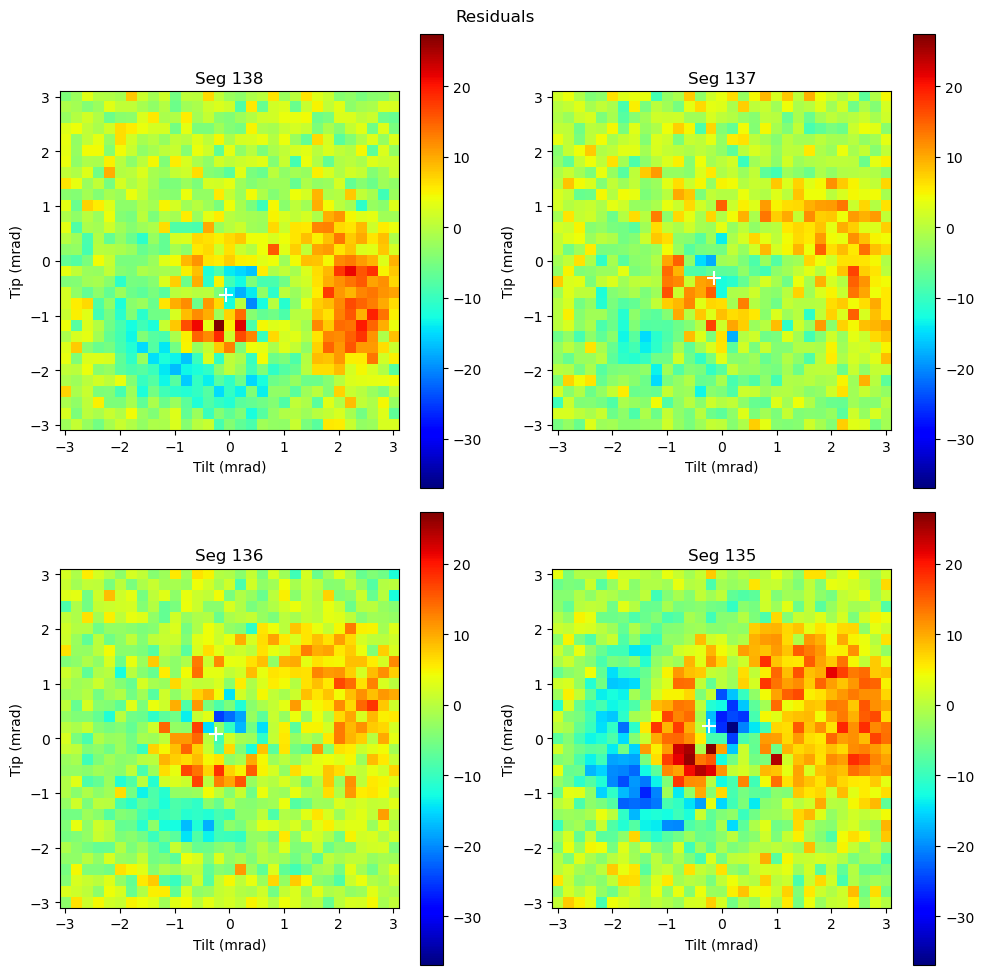

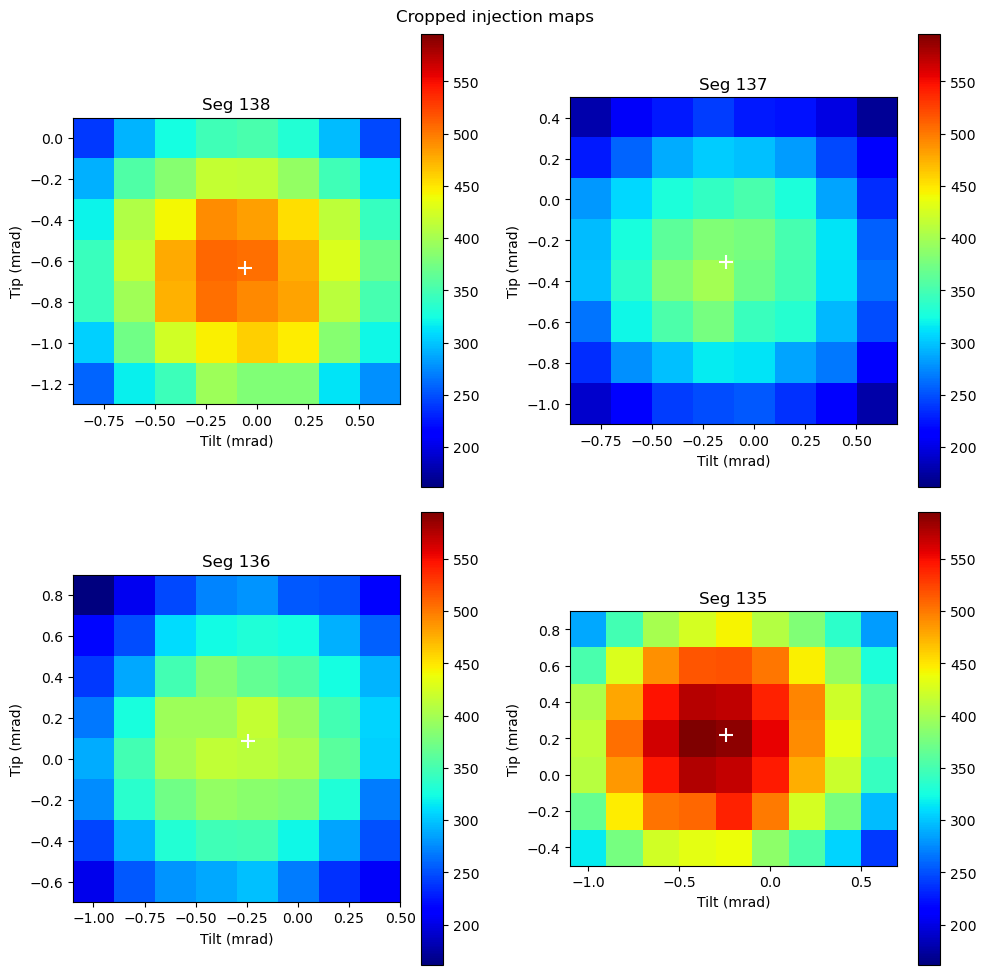

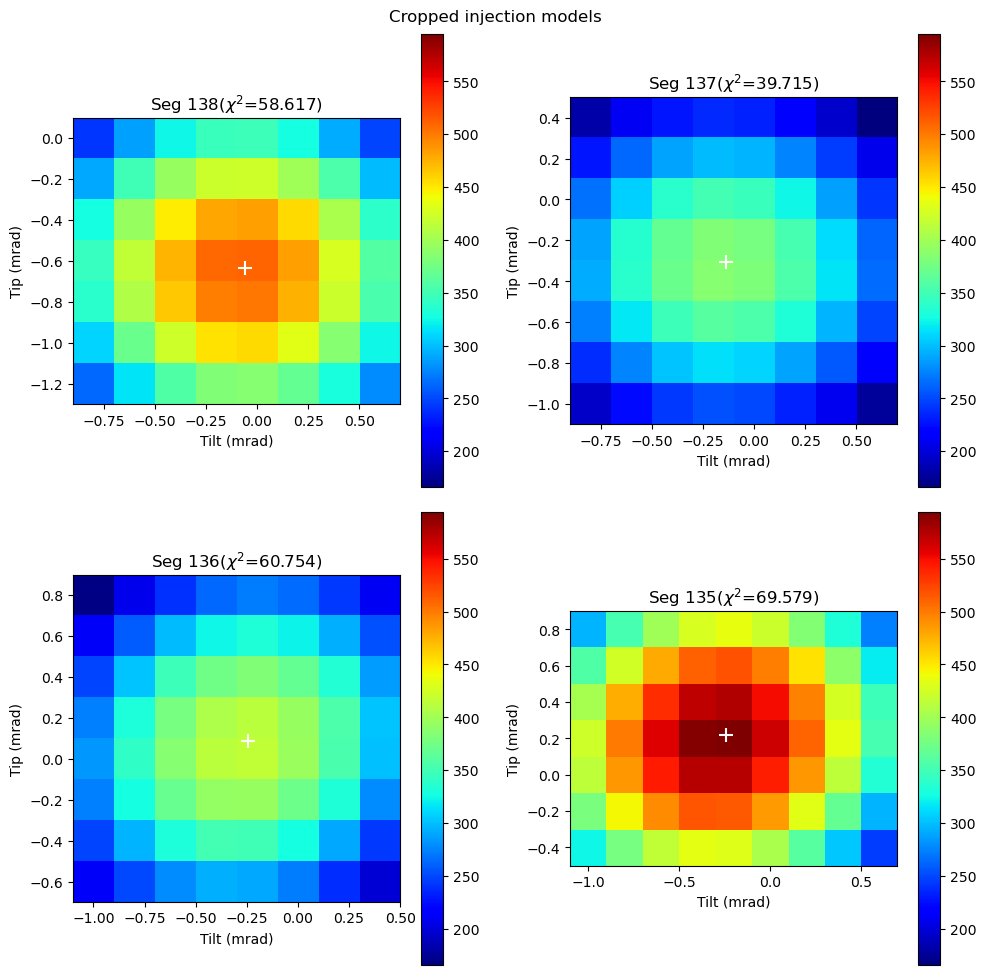

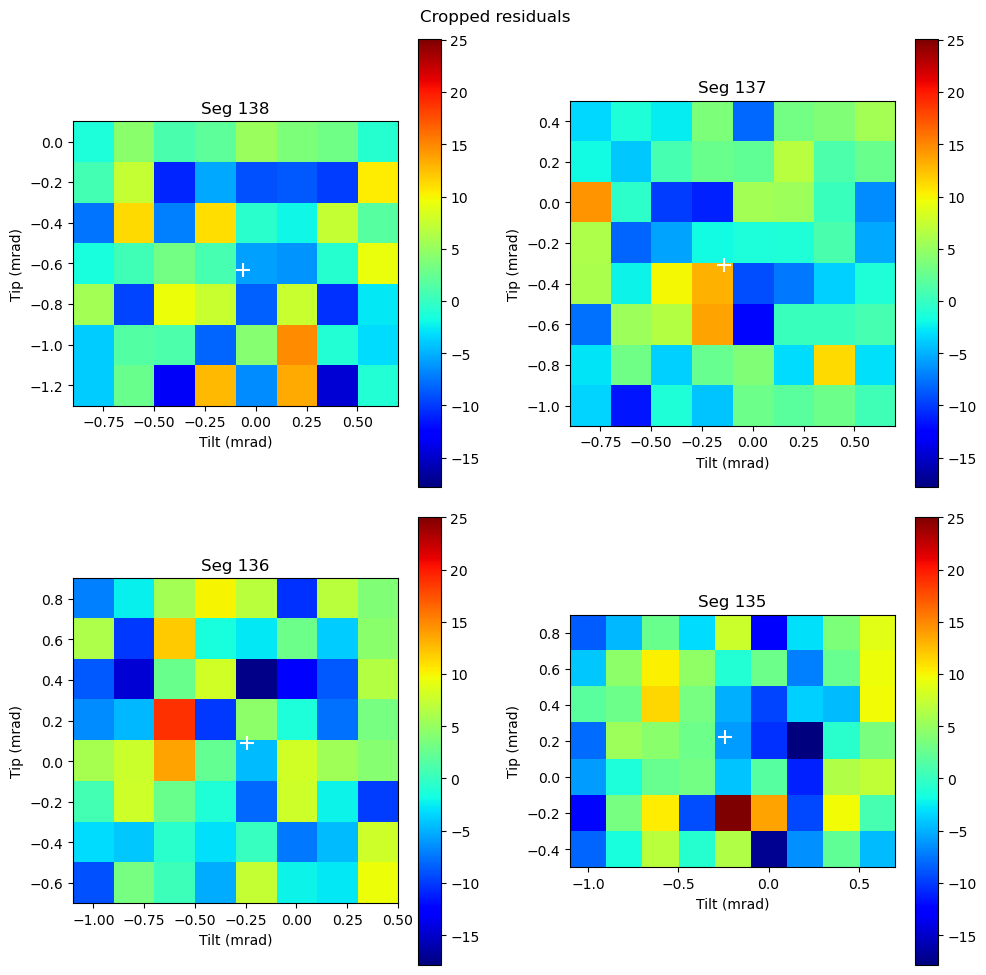

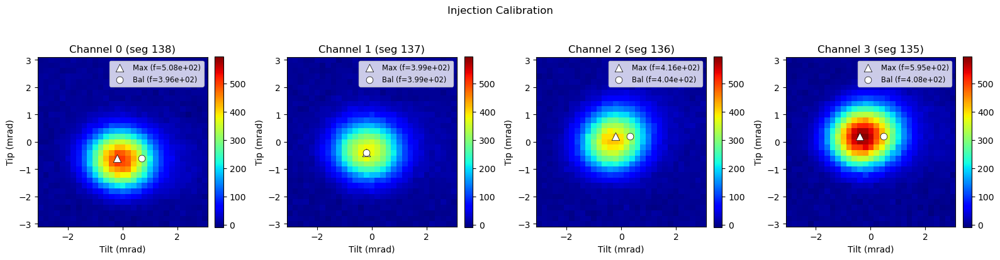

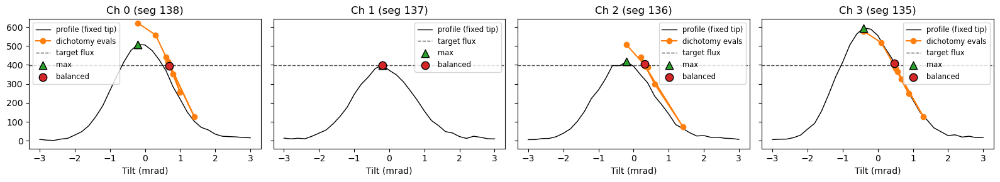

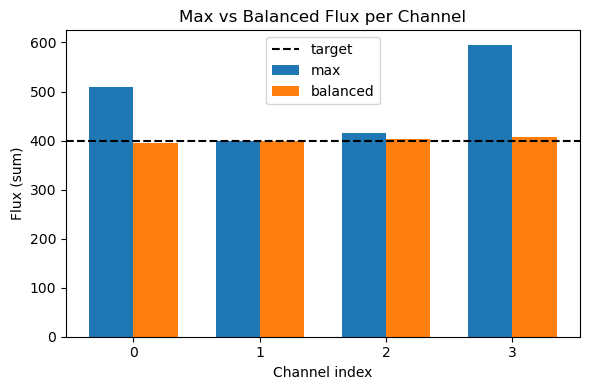

Successfully saved in FITS
Injection ZERO on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])


In [7]:
# Injection calibration
avg_frame = 1
avg_frames_bal = 5
out_inj = inj.calibrate(verbose=True, plot=True, save_path=path, 
                        avg_frames=avg_frame, avg_frames_bal=avg_frames_bal,
                        tilt_tol = 0.5e-3, no_balancing=False)

inj.zero()

# TOPs calibration

Injection BALANCED on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
  - Scanning shifter 17...
  ✅ Shifter 17 calibrated: Period=0.5940 W -> Coeff=0.0945 W/rad
  - Scanning shifter 18...
  ✅ Shifter 18 calibrated: Period=0.5973 W -> Coeff=0.0951 W/rad
  - Scanning shifter 19...
  ✅ Shifter 19 calibrated: Period=0.5944 W -> Coeff=0.0946 W/rad
  - Scanning shifter 20...
  ✅ Shifter 20 calibrated: Period=0.5998 W -> Coeff=0.0955 W/rad


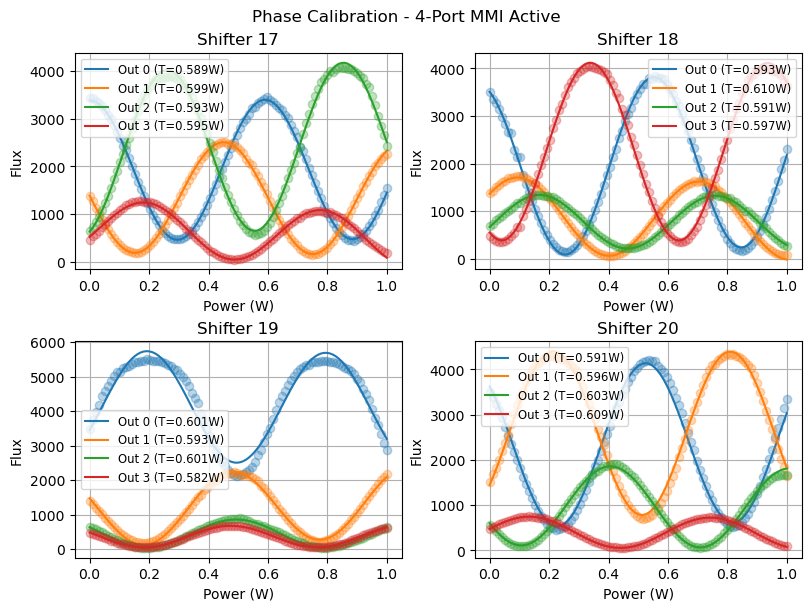

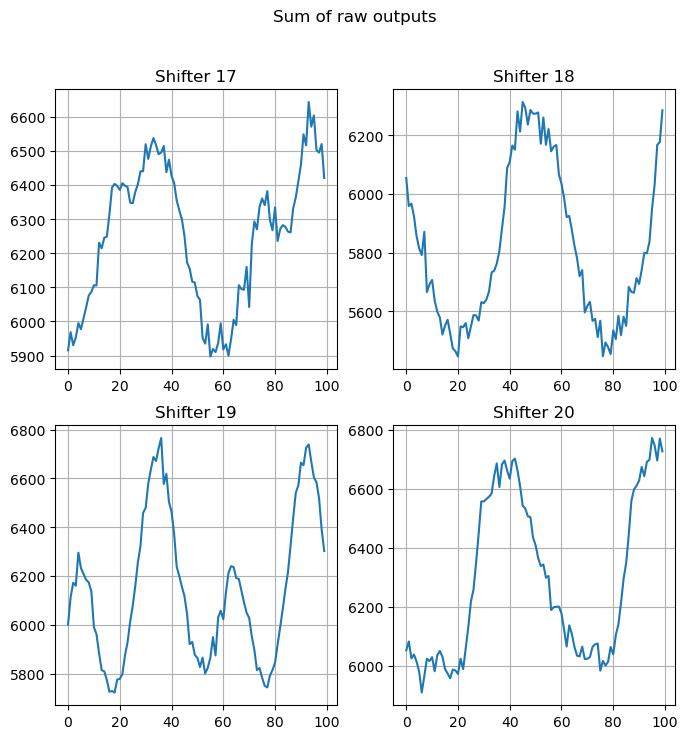

In [25]:
chip = phobos.Arch6()
chip.turn_off()

inj.set_balanced()

avg_frames = 5
# TOPAs calibration
chip_coeffs, chip_scans, chip_power_range = chip.phase_calibration(plot=True, verbose=False, crop_mode='centers', nroi=4)

np.save(path / "chip_coeffs.npy", chip_coeffs)
np.savez(path / "chip_scans.npz", chip_scans=chip_scans, chip_power_range=chip_power_range)

s = chip_scans[:,:,::-1].sum(2)
plt.figure(figsize=(8,8))
plt.suptitle("Sum of raw outputs")
for i in range(4):
    plt.subplot(2,2,i+1)
    plt.plot(s[i].T)
    plt.grid()
    plt.title(f"Shifter {chip.shifters[i].channel}")

chip.turn_off()

# Pair scan

## With DM

Injection BALANCED on channels [0, 1] (segments [138, 137])
Injection BALANCED on channels [0, 1] (segments [138, 137])
Injection BALANCED on channels [0, 2] (segments [138, 136])
Injection BALANCED on channels [0, 2] (segments [138, 136])
Injection BALANCED on channels [0, 3] (segments [138, 135])
Injection BALANCED on channels [0, 3] (segments [138, 135])
Injection BALANCED on channels [1, 2] (segments [137, 136])
Injection BALANCED on channels [1, 2] (segments [137, 136])
Injection BALANCED on channels [1, 3] (segments [137, 135])
Injection BALANCED on channels [1, 3] (segments [137, 135])
Injection BALANCED on channels [2, 3] (segments [136, 135])
Injection BALANCED on channels [2, 3] (segments [136, 135])
Injection BALANCED on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])


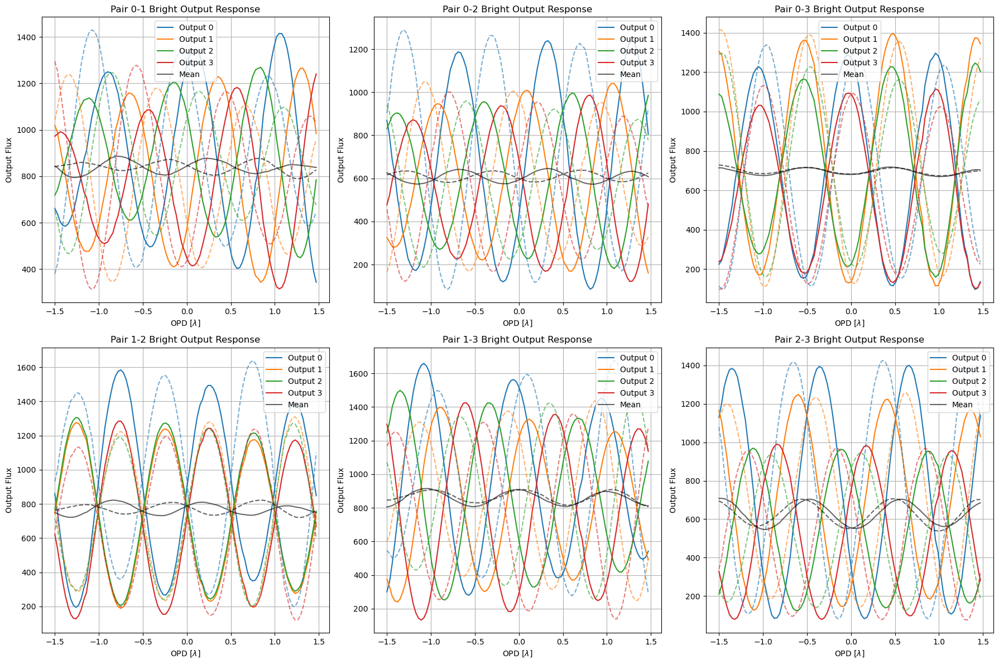

In [11]:
pairs = [(0,1), (0,2), (0,3), (1,2), (1,3), (2,3)]
nb_lam = 3.
crop_mode = 'rectangles_integrated'
shapes = cam.get_outputs(flux_mode='mean', crop_mode=crop_mode)
n_roi = shapes.shape[0] - 1
nframes = 10

res_pair_scan = {}

fig, axs = plt.subplots(2, 3, figsize=(18, 12))
axs = axs.flatten()
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
for i, pair in enumerate(pairs):
    inj.off(verbose=False)
    inj.set_balanced(np.array(pair))

    ref_tip = (dm[inj_seg[pair[0]]].get_tip(), dm[inj_seg[pair[1]]].get_tip())
    ref_tilt = (dm[inj_seg[pair[0]]].get_tilt(), dm[inj_seg[pair[1]]].get_tilt())

    ref_cart = dm[inj_seg[pair[1]]].get_piston()
    start = ref_cart - nb_lam * lam/2./2.
    piston_range = np.linspace(start, start + nb_lam * lam/2., 100, endpoint=False)  # [nm]
    opd_range = (piston_range - ref_cart) * 2


    # Scan on first input
    outs = np.empty((len(piston_range), n_roi))
    for p, piston in enumerate(piston_range):
        dm[inj_seg[pair[0]]].set_ptt(piston, ref_tip[0], ref_tilt[0])
        if p == 0:
            time.sleep(0.1)
        outs[p] = cam.get_outputs(flux_mode='mean', crop_mode=crop_mode, stack=nframes)[:n_roi]

    dm[inj_seg[pair[0]]].set_ptt(ref_cart, ref_tip[0], ref_tilt[0])
    time.sleep(0.1)

    data = np.hstack((opd_range[:,None], outs.copy()))
    res_pair_scan[(pair[0], pair[1])] = data

    for o in range(n_roi):
        axs[i].plot(opd_range / lam, outs[:, o], color=colors[o], label=f'Output {o}')
    axs[i].plot(opd_range / lam, outs.mean(1), color='k', linestyle='-', alpha=0.6, label='Mean')

    # Scan on second input
    inj.off(verbose=False)
    inj.set_balanced(np.array(pair))

    outs = np.empty((len(piston_range), n_roi))
    for p, piston in enumerate(piston_range):
        dm[inj_seg[pair[1]]].set_ptt(piston, ref_tip[1], ref_tilt[1])
        if p == 0:
            time.sleep(0.1)
        outs[p] = cam.get_outputs(flux_mode='mean', crop_mode=crop_mode, stack=nframes)[:n_roi]

    dm[inj_seg[pair[0]]].set_ptt(ref_cart, ref_tip[0], ref_tilt[0])
    time.sleep(0.1)

    data = np.hstack((opd_range[:,None], outs.copy()))
    res_pair_scan[(pair[1], pair[0])] = data

    for o in range(n_roi):
        axs[i].plot(opd_range / lam, outs[:, o], color=colors[o], linestyle='--', alpha=0.6)
    axs[i].plot(opd_range / lam, outs.mean(1), color='k', linestyle='--', alpha=0.6)
    
    axs[i].set_title(f'Pair {pair[0]}-{pair[1]} Bright Output Response')
    axs[i].set_xlabel(r'OPD [$\lambda$]')
    axs[i].set_ylabel('Output Flux')
    axs[i].legend()
    axs[i].grid()

fig.tight_layout()
filename = 'pair_dm_scan_start%.0f_nb_lam%s.png'%(start, nb_lam)
fig.savefig(path / filename, dpi=150, format='png')

filename = 'pair_dm_scan_data_start%.0f_nb_lam%s.pkl'%(start, nb_lam)
with open(path / filename, 'wb') as f:
    pickle.dump(res_pair_scan, f)


inj.set_balanced()

# Finding white fringe
## Scanning all pairs with different reference positions

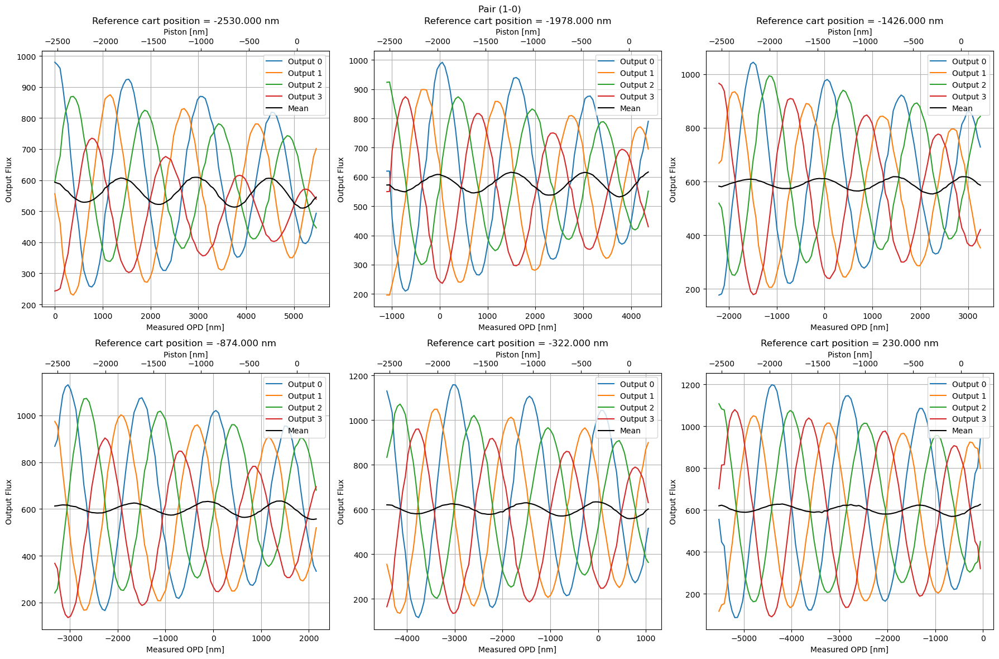

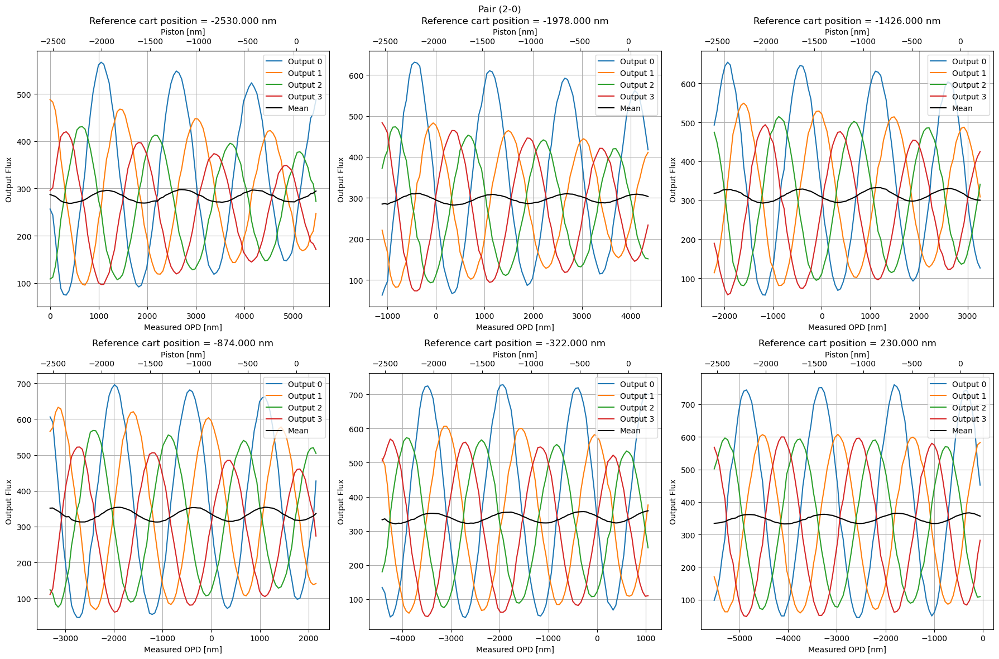

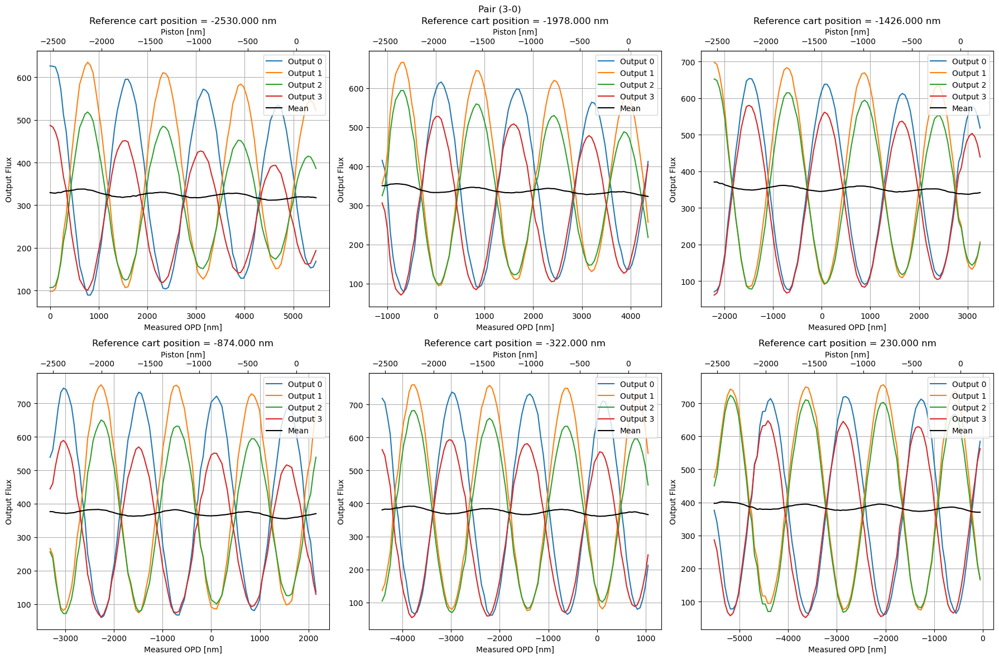

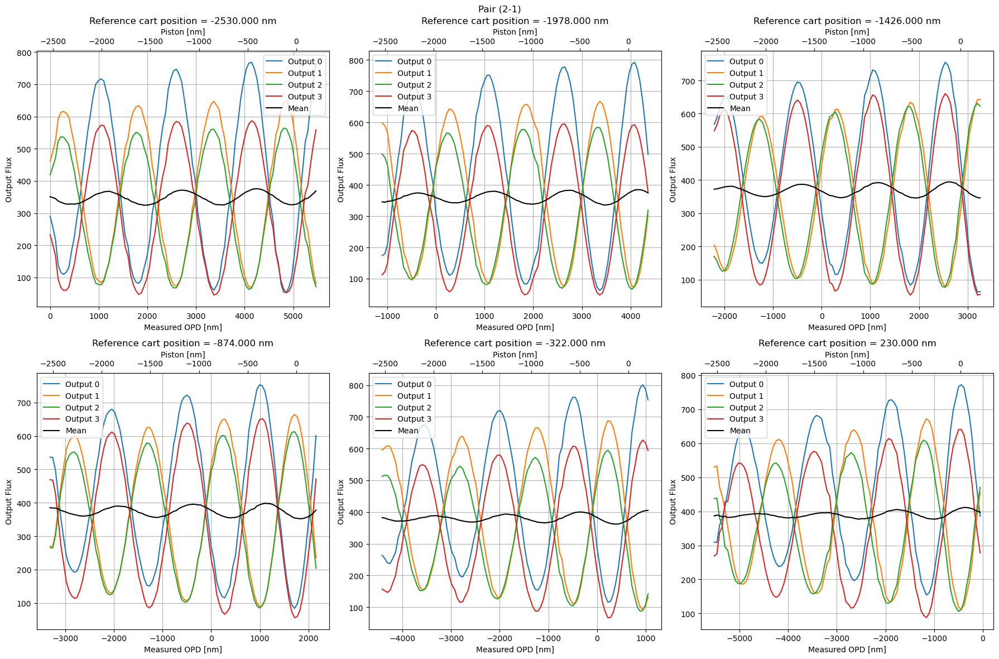

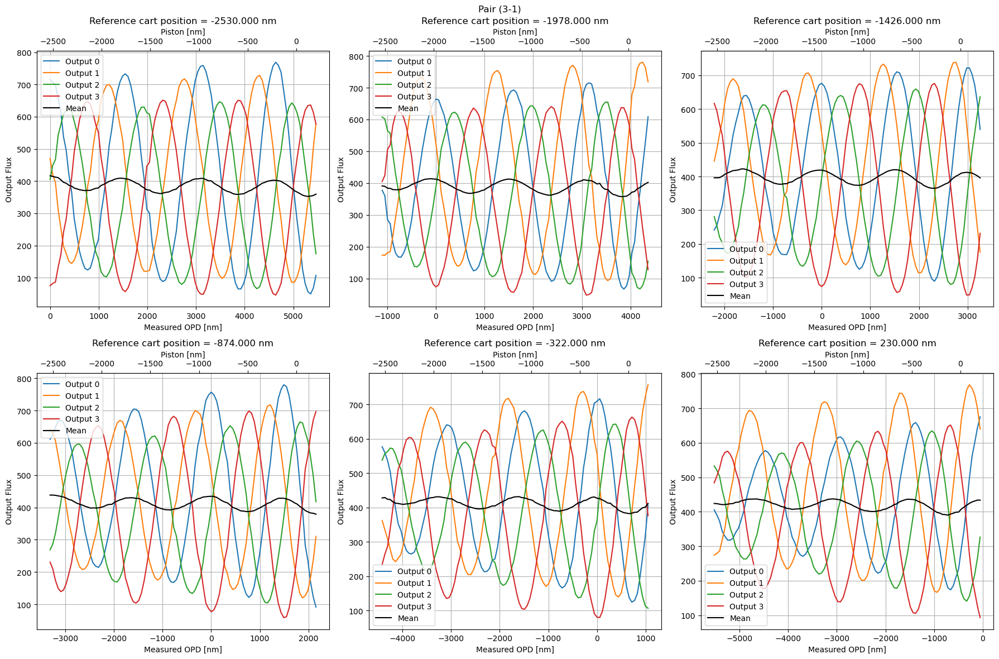

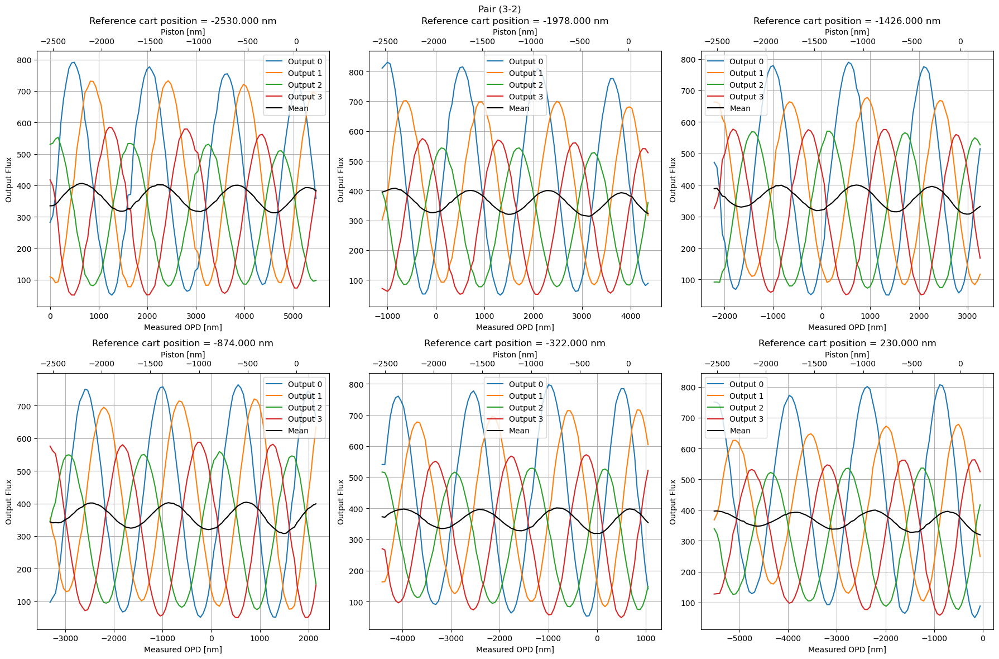

In [35]:
# Scan with the second segment
ref_positions = np.linspace(-2530, 230, 6)
pairs = [(0,1), (0,2), (0,3), (1,2), (1,3), (2,3)]
crop_mode = 'rectangles_integrated'
n_roi = cam.get_outputs(flux_mode='mean', crop_mode=crop_mode).size - 1
nframes = 5

for pair in pairs:
    res_pair_scan = {}

    fig, axs = plt.subplots(2, 3, figsize=(18, 12))
    fig.suptitle(f'Pair ({pair[1]}-{pair[0]})')
    axs = axs.flatten()
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
    for i, ref_cart in enumerate(ref_positions):
        inj.off(verbose=False)
        inj.set_balanced(np.array(pair), verbose=False)

        ref_tip = (dm[inj_seg[pair[0]]].get_tip(), dm[inj_seg[pair[1]]].get_tip())
        ref_tilt = (dm[inj_seg[pair[0]]].get_tilt(), dm[inj_seg[pair[1]]].get_tilt())

        piston_range = np.linspace(-2530, 230, 100, endpoint=False)  # [nm]
        opd_range = (piston_range - ref_cart) * 2

        # Scan on second input
        inj.off(verbose=False)
        inj.set_balanced(np.array(pair), verbose=False)

        dm[inj_seg[pair[0]]].set_ptt(ref_cart, ref_tip[1], ref_tilt[1])

        outs = np.empty((len(piston_range), n_roi))
        for p, piston in enumerate(piston_range):
            dm[inj_seg[pair[1]]].set_ptt(piston, ref_tip[1], ref_tilt[1])
            if p == 0:
                time.sleep(0.1)        
            outs[p] = cam.get_outputs(flux_mode='mean', crop_mode=crop_mode, stack=nframes)[:n_roi]

        dm[inj_seg[pair[1]]].set_ptt(ref_cart, ref_tip[0], ref_tilt[0]) # Re-init segment
        time.sleep(0.1)

        data = np.hstack((opd_range[:,None], outs.copy()))
        res_pair_scan[ref_cart] = data

        for o in range(n_roi):
            axs[i].plot(opd_range, outs[:, o], color=colors[o], label=f'Output {o}')
        axs[i].plot(opd_range, outs.mean(1), color='k', label='Mean')

        axs[i].set_title(f'Reference cart position = {ref_cart:.3f} nm')
        axs[i].set_xlabel('Measured OPD [nm]')
        axs[i].set_ylabel('Output Flux')
        axs[i].legend()
        axs[i].grid()
        opd_to_piston = lambda opd, ref=ref_cart: opd / 2.0 + ref
        piston_to_opd = lambda piston, ref=ref_cart: (piston - ref) * 2.0
        secax = axs[i].secondary_xaxis('top', functions=(opd_to_piston, piston_to_opd))
        secax.set_xlabel('Piston [nm]')

    fig.tight_layout()
    filename = 'dm_scan_white_light_pair_%d_%d.png'%(pair[1], pair[0])
    fig.savefig(path / filename, dpi=150, format='png')

    filename = 'dm_scan_white_light_pair_%d_%d.pkl'%(pair[1], pair[0])
    with open(path / filename, 'wb') as f:
        pickle.dump(res_pair_scan, f)


    inj.set_balanced(verbose=False)

## Going to the white light on some pairs

In [48]:
def scan_dm_white_light(start, end, ref_cart, nstack):
    inj.off()
    inj.set_balanced(np.array(pair))

    ref_tip = (dm[inj_seg[pair[0]]].get_tip(), dm[inj_seg[pair[1]]].get_tip())
    ref_tilt = (dm[inj_seg[pair[0]]].get_tilt(), dm[inj_seg[pair[1]]].get_tilt())

    dm[inj_seg[pair[0]]].set_ptt(ref_cart, ref_tip[1], ref_tilt[1])
    piston_range = np.linspace(start, end, 100, endpoint=True)  # [nm]
    opd_range = (piston_range - ref_cart) * 2

    # Scan on first input
    outs = np.empty((len(piston_range), n_roi))
    spectral_outs = np.empty((len(piston_range), n_roi, spectral_sz))
    for p, piston in enumerate(tqdm(piston_range)):
        dm[inj_seg[pair[1]]].set_ptt(piston, ref_tip[0], ref_tilt[0])
        if p == 0:
            time.sleep(0.1)
        frame = cam.get_outputs(flux_mode='mean', crop_mode=crop_mode, stack=nstack)[:n_roi]
        outs[p] = frame.mean(1)
        spectral_outs[p] = frame

    dm[inj_seg[pair[1]]].set_ptt(ref_cart, ref_tip[0], ref_tilt[0]) # Re-init segment
    time.sleep(0.1)

    max_bright_pos = piston_range[np.argmax(outs[:,3])]
    max_null_pos = piston_range[np.argmax(outs[:,0])]
    min_bright_pos = piston_range[np.argmin(outs[:,3])]
    min_null_pos = piston_range[np.argmin(outs[:,0])]

    print('Max flux for output 3:', max_bright_pos)
    print('Max flux for output 0:', max_null_pos)
    print('Min flux for output 3:', min_bright_pos)
    print('Min flux for output 0:', min_null_pos)


    return outs, spectral_outs, (max_bright_pos, min_bright_pos), (max_null_pos, min_null_pos), piston_range, opd_range

def set_dm_to_white_fringe(pair, pos, ref_cart):
    inj.off()
    inj.set_balanced(np.array(pair))

    ref_tip = (dm[inj_seg[pair[0]]].get_tip(), dm[inj_seg[pair[1]]].get_tip())
    ref_tilt = (dm[inj_seg[pair[0]]].get_tilt(), dm[inj_seg[pair[1]]].get_tilt())

    dm[inj_seg[pair[1]]].set_ptt(pos, ref_tip[0], ref_tilt[0])
    dm[inj_seg[pair[0]]].set_ptt(ref_cart, ref_tip[1], ref_tilt[1])


In [47]:
def plot_spectral_maps_grid(
    opd_range: np.ndarray,
    spectral_outs: np.ndarray,
    spectral_axs: np.ndarray,
    spec_law: np.ndarray,
    pair: tuple[int, int],
    ref_cart: float,
    piston_range: np.ndarray,
    path: Path,
    dpi: int = 300,
    filename_prefix: str = "opd0_dm_scan_spectral_pair",
    xlabel: str = "Measured OPD [nm]",
    sec_axis: bool = True
) -> tuple[plt.Figure, np.ndarray]:
    """
    Plot spectral maps in a single 2x2 figure and save it.

    Parameters
    ----------
    opd_range : np.ndarray
        OPD values in nanometers.
    spectral_outs : np.ndarray
        Spectral flux array with shape (n_samples, n_outputs, n_wavelengths).
    spectral_axs : np.ndarray
        Wavelength axis per output channel.
    spec_law : np.ndarray
        Spectral calibration coefficients.
    pair : tuple[int, int]
        Input pair index.
    ref_cart : float
        Reference piston position in nanometers.
    piston_range : np.ndarray
        Scanned piston values in nanometers.
    path : Path
        Output directory.
    dpi : int, optional
        Figure DPI.
    filename_prefix : str, optional
        Prefix used for saved file names.

    Returns
    -------
    tuple[matplotlib.figure.Figure, np.ndarray]
        Generated figure and axes.
    """
    suptitle_fs = 22
    title_fs = 18
    label_fs = 14
    tick_fs = 12

    opd_step = float(opd_range[1] - opd_range[0]) if opd_range.size > 1 else 1.0
    opd_to_piston = lambda opd, rc=ref_cart: opd / 2.0 + rc
    piston_to_opd = lambda piston, rc=ref_cart: (piston - rc) * 2.0

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))
    axs = axs.flatten()

    fig.suptitle(
        f"Pair ({pair[0]}-{pair[1]})\nReference cart position = {ref_cart:.3f} nm",
        fontsize=suptitle_fs,
    )

    n_outputs = min(4, spectral_outs.shape[1])

    for o in range(n_outputs):
        im = axs[o].imshow(
            spectral_outs[:, o, :].T,
            aspect="auto",
            origin="lower",
            extent=[
                opd_range.min() - opd_step / 2,
                opd_range.max() + opd_step / 2,
                spectral_axs[o, 0] - spec_law[o, 0] / 2,
                spectral_axs[o, -1] + spec_law[o, 0] / 2,
            ],
            vmin=spectral_outs.min(),
            vmax=spectral_outs.max(),
        )

        axs[o].tick_params(labelsize=tick_fs)
        axs[o].set_title(f"Output {o}", fontsize=title_fs)
        axs[o].set_xlabel(xlabel, fontsize=label_fs)
        axs[o].set_ylabel("Wavelength [nm]", fontsize=label_fs)
        axs[o].grid()

        cbar = fig.colorbar(im, ax=axs[o])
        cbar.set_label("Flux", fontsize=label_fs)
        cbar.ax.tick_params(labelsize=tick_fs)

        if sec_axis:
            secax = axs[o].secondary_xaxis("top", functions=(opd_to_piston, piston_to_opd))
            secax.set_xlabel("DM position [nm]", fontsize=label_fs)
            secax.tick_params(labelsize=tick_fs)

    for o in range(n_outputs, 4):
        axs[o].axis("off")

    fig.tight_layout()
    filename = (
        f"{filename_prefix}_{pair[0]}-{pair[1]}_ref_{int(ref_cart)}nm_range_"
        f"{int(piston_range[0])}_{int(piston_range[-1])}nm.png"
    )
    fig.savefig(path / filename, dpi=dpi, format="png")
    return fig, axs

def plot_integrated_flux(
    opd_range: np.ndarray,
    outs: np.ndarray,
    n_roi: int,
    pair: tuple[int, int],
    ref_cart: float,
    piston_range: np.ndarray,
    path: Path,
    filename_prefix: str = "opd0_dm_scan_pair",
    dpi: int = 300,
    xlabel: str = "Measured OPD [nm]",
    sec_axis: bool = True    
) -> tuple[plt.Figure, plt.Axes]:
    """
    Plot integrated flux versus OPD with a secondary piston axis and save the figure.

    Parameters
    ----------
    opd_range : np.ndarray
        OPD values in nanometers.
    outs : np.ndarray
        Output flux array with shape (n_samples, n_roi).
    n_roi : int
        Number of output channels.
    pair : tuple[int, int]
        Input pair index, e.g. (2, 0).
    ref_cart : float
        Reference piston position in nanometers.
    piston_range : np.ndarray
        Piston scan values in nanometers.
    path : Path
        Directory where the figure is saved.
    filename_prefix : str, optional
        Output filename prefix.
    dpi : int, optional
        Figure DPI.

    Returns
    -------
    tuple[matplotlib.figure.Figure, matplotlib.axes.Axes]
        Generated figure and axis.
    """
    suptitle_fs = 22
    title_fs = 20
    label_fs = 18
    tick_fs = 16
    legend_fs = 16

    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    fig.suptitle(f"Pair ({pair[0]}-{pair[1]})", fontsize=suptitle_fs)

    colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    for o in range(n_roi):
        ax.plot(opd_range, outs[:, o], color=colors[o], label=f"Output {o}")
    ax.plot(opd_range, outs.mean(1), color="k", linestyle="-", alpha=0.6, label="Mean")

    ax.tick_params(labelsize=tick_fs)
    ax.set_title(f"Reference cart position = {ref_cart:.3f} nm", fontsize=title_fs)
    ax.set_xlabel(xlabel, fontsize=label_fs)
    ax.set_ylabel("Output Flux", fontsize=label_fs)
    ax.legend(loc="upper right", fontsize=legend_fs)
    ax.grid()

    if sec_axis:
        opd_to_piston = lambda opd, rc=ref_cart: opd / 2.0 + rc
        piston_to_opd = lambda piston, rc=ref_cart: (piston - rc) * 2.0
        secax = ax.secondary_xaxis("top", functions=(opd_to_piston, piston_to_opd))
        secax.set_xlabel("Piston [nm]", fontsize=label_fs)
        secax.tick_params(labelsize=tick_fs)

    fig.tight_layout()
    filename = (
        f"{filename_prefix}_{pair[0]}-{pair[1]}_ref_{int(ref_cart)}nm_range_"
        f"{int(piston_range[0])}_{int(piston_range[-1])}nm.png"
    )
    fig.savefig(path / filename, dpi=dpi, format="png")
    return fig, ax

def plot_spectral_maps_by_output(
    opd_range: np.ndarray,
    spectral_outs: np.ndarray,
    spectral_axs: np.ndarray,
    spec_law: np.ndarray,
    pair: tuple[int, int],
    ref_cart: float,
    piston_range: np.ndarray,
    path: Path,
    dpi: int = 300,
    filename_prefix: str = "opd0_dm_scan_spectral_pair",
    xlabel: str = "Measured OPD [nm]",
    sec_axis: bool = True      
) -> list[plt.Figure]:
    """
    Plot one spectral map per output channel and save each figure.

    Parameters
    ----------
    opd_range : np.ndarray
        OPD values in nanometers.
    spectral_outs : np.ndarray
        Spectral flux array with shape (n_samples, n_outputs, n_wavelengths).
    spectral_axs : np.ndarray
        Wavelength axis per output channel.
    spec_law : np.ndarray
        Spectral calibration coefficients.
    pair : tuple[int, int]
        Input pair index.
    ref_cart : float
        Reference piston position in nanometers.
    piston_range : np.ndarray
        Scanned piston values in nanometers.
    path : Path
        Output directory.
    dpi : int, optional
        Figure DPI.
    filename_prefix : str, optional
        Prefix used for saved file names.

    Returns
    -------
    list[matplotlib.figure.Figure]
        Generated figures.
    """
    suptitle_fs = 22
    title_fs = 20
    label_fs = 18
    tick_fs = 16
    n_outputs = min(4, spectral_outs.shape[1])

    opd_step = float(opd_range[1] - opd_range[0]) if opd_range.size > 1 else 1.0
    opd_to_piston = lambda opd, rc=ref_cart: opd / 2.0 + rc
    piston_to_opd = lambda piston, rc=ref_cart: (piston - rc) * 2.0

    figures: list[plt.Figure] = []

    for k in range(n_outputs):
        fig, ax = plt.subplots(1, 1, figsize=(10, 10))
        fig.suptitle(f"Pair ({pair[0]}-{pair[1]}) - Output {k}", fontsize=suptitle_fs)

        im = ax.imshow(
            spectral_outs[:, k, :].T,
            aspect="auto",
            origin="lower",
            extent=[
                opd_range.min() - opd_step / 2,
                opd_range.max() + opd_step / 2,
                spectral_axs[k, 0] - spec_law[k, 0] / 2,
                spectral_axs[k, -1] + spec_law[k, 0] / 2,
            ],
            vmin=spectral_outs.min(),
            vmax=spectral_outs.max(),
        )

        ax.tick_params(labelsize=tick_fs)
        ax.set_title(f"Reference cart position = {ref_cart:.3f} nm", fontsize=title_fs)
        ax.set_xlabel(xlabel, fontsize=label_fs)
        ax.set_ylabel("Wavelength [nm]", fontsize=label_fs)
        ax.grid()

        cbar = fig.colorbar(im, ax=ax)
        cbar.set_label("Flux", fontsize=label_fs)
        cbar.ax.tick_params(labelsize=tick_fs)

        if sec_axis:
            secax = ax.secondary_xaxis("top", functions=(opd_to_piston, piston_to_opd))
            secax.set_xlabel("DM position [nm]", fontsize=label_fs)
            secax.tick_params(labelsize=tick_fs)

        fig.tight_layout()
        filename = (
            f"{filename_prefix}_{pair[0]}-{pair[1]}_ref_{int(ref_cart)}nm_range_"
            f"{int(piston_range[0])}_{int(piston_range[-1])}nm_output{k}.png"
        )
        fig.savefig(path / filename, dpi=dpi, format="png")
        figures.append(fig)

    return figures

### Pair 0 (ref) - 2

In [56]:
ref_cart = 230
start, end = -2530, 230
# start, end = max_flux_pos - 5/8. * lam, max_flux_pos + lam / 4
spec_law = np.load(path / 'spec_cal_coeffs_and_errors.npy')[0]

pair = (0,2)
crop_mode = 'rectangles'
shapes = cam.get_outputs(flux_mode='mean', crop_mode=crop_mode).shape 
n_roi = shapes[0] - 1
spectral_sz = shapes[1]
crop_areas = np.array(phobos.Config().get('cred3.output_rectangles'))
crop_areas = crop_areas[:n_roi]
crop_areas = crop_areas[:,[0,2]] # Got the spectral bounds of each track
spectral_axs = np.array([np.arange(crop_areas[i,0], crop_areas[i,-1]) for i in range(crop_areas.shape[0])])
spectral_axs = np.array([np.polyval(spec_law[i], spectral_axs[i]) for i in range(spectral_axs.shape[0])])

outs20, spectral_outs20, bright_out20, null_out20, piston_range20, opd_range20 = scan_dm_white_light(start, end, ref_cart, nstack=10)
filename = f'opd0_dm_scan_pair_{pair[0]}-{pair[1]}_ref_{int(ref_cart)}nm_range_{int(start)}_{int(end)}nm.npz'
np.savez(path / filename, 
         data=outs20, 
         spectral_data=spectral_outs20, 
         ref_cart=ref_cart, 
         piston_range=piston_range20, 
         opd_range=opd_range20)
print('Data saved in', path / filename)


Injection OFF on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
Injection BALANCED on channels [0, 2] (segments [138, 136])


  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:02<00:00, 46.24it/s]


Max flux for output 3: -1777.2727272727273
Max flux for output 0: -606.3636363636363
Min flux for output 3: -2167.5757575757575
Min flux for output 0: -996.6666666666667
Data saved in /mnt/disk1/archive/2026-09-15_c64cfaf/1_kernel_null/opd0_dm_scan_pair_0-2_ref_230nm_range_-2530_230nm.npz


In [97]:
pair = (0,2)
# set_dm_to_white_fringe(pair, -1482, ref_cart)
# set_dm_to_white_fringe(pair, bright_out20[0], ref_cart)
set_dm_to_white_fringe(pair, null_out20[1], ref_cart)

Injection OFF on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
Injection BALANCED on channels [0, 2] (segments [138, 136])


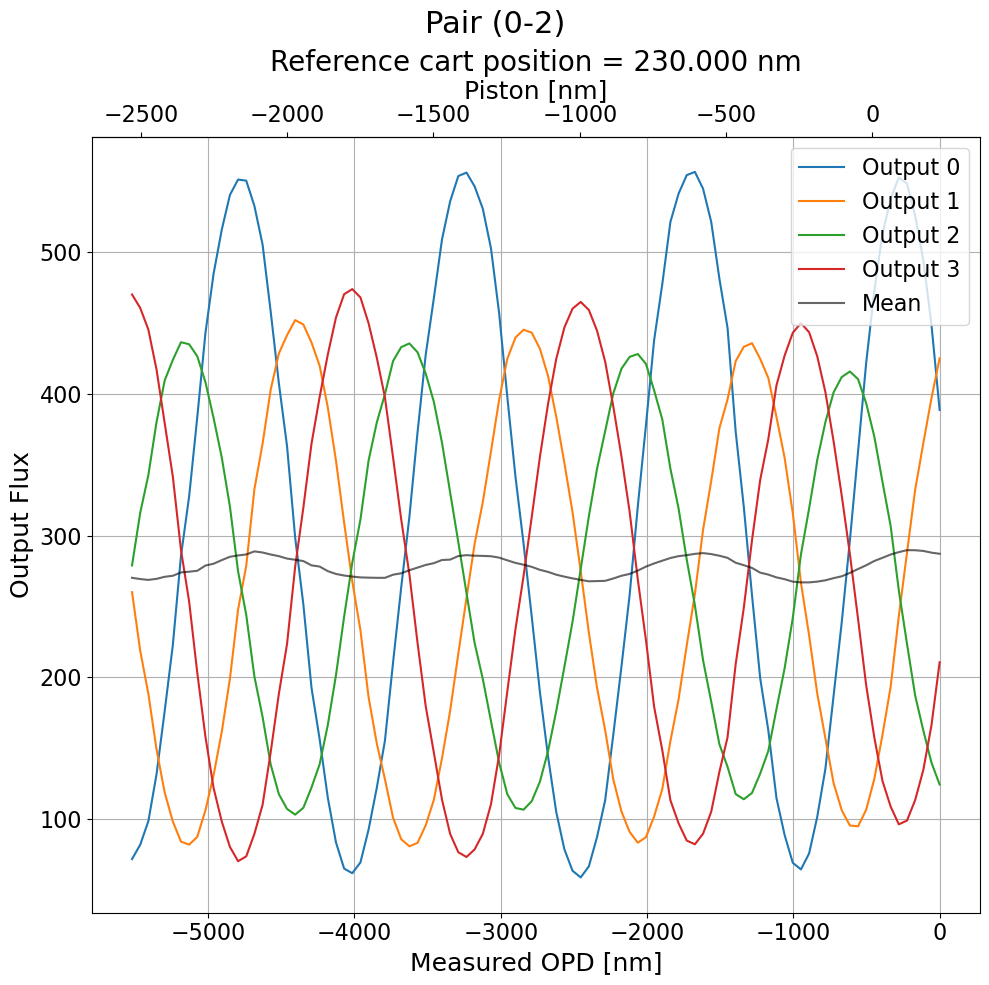

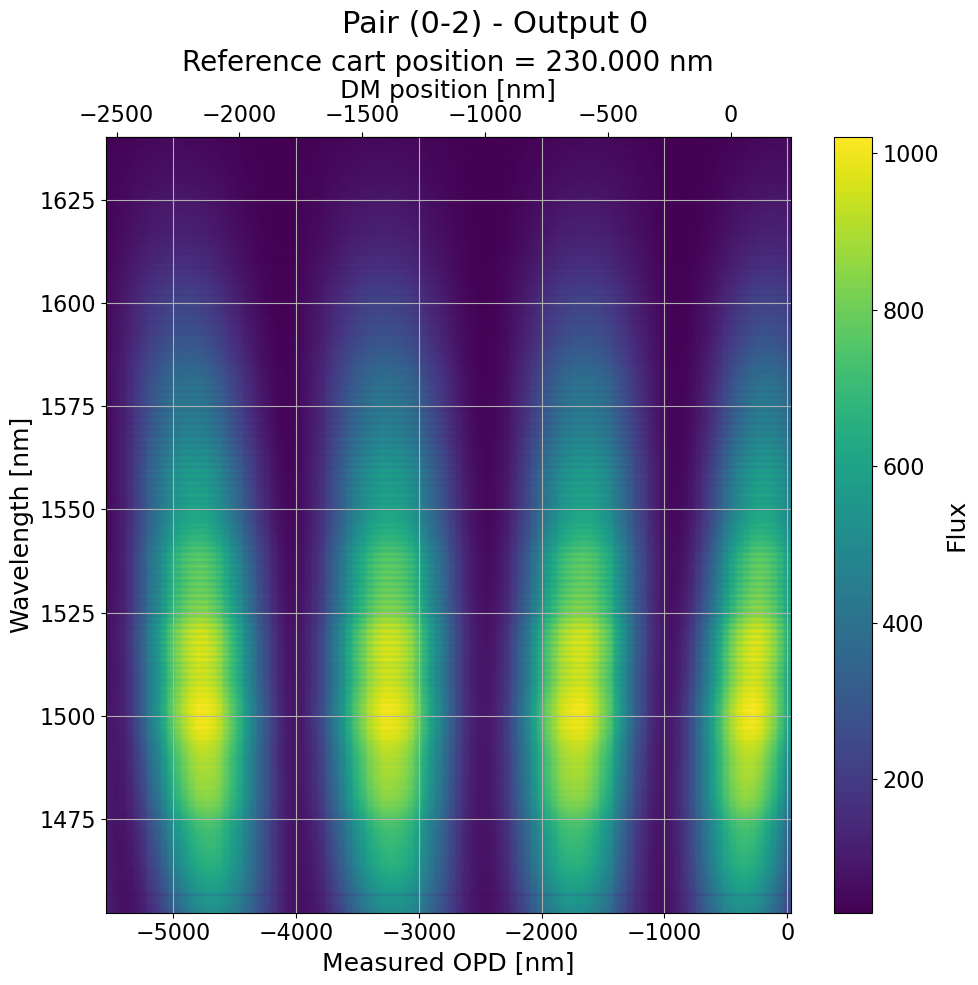

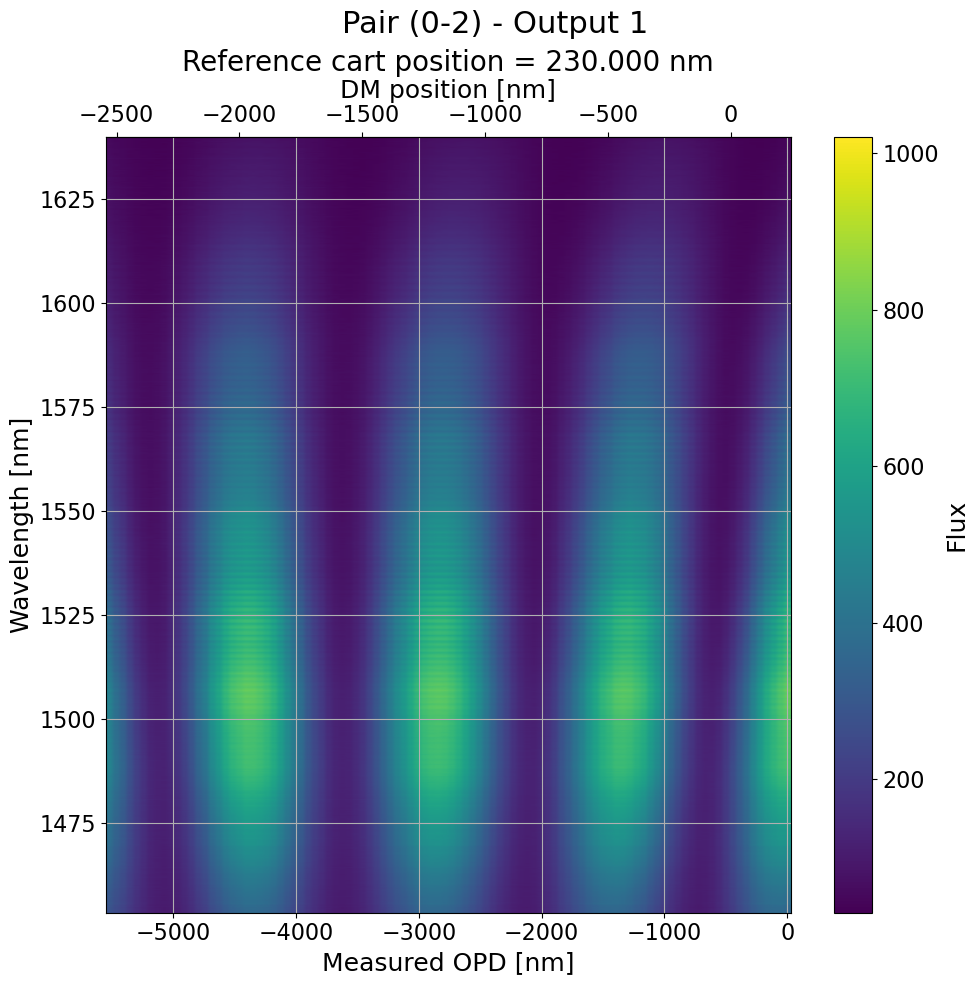

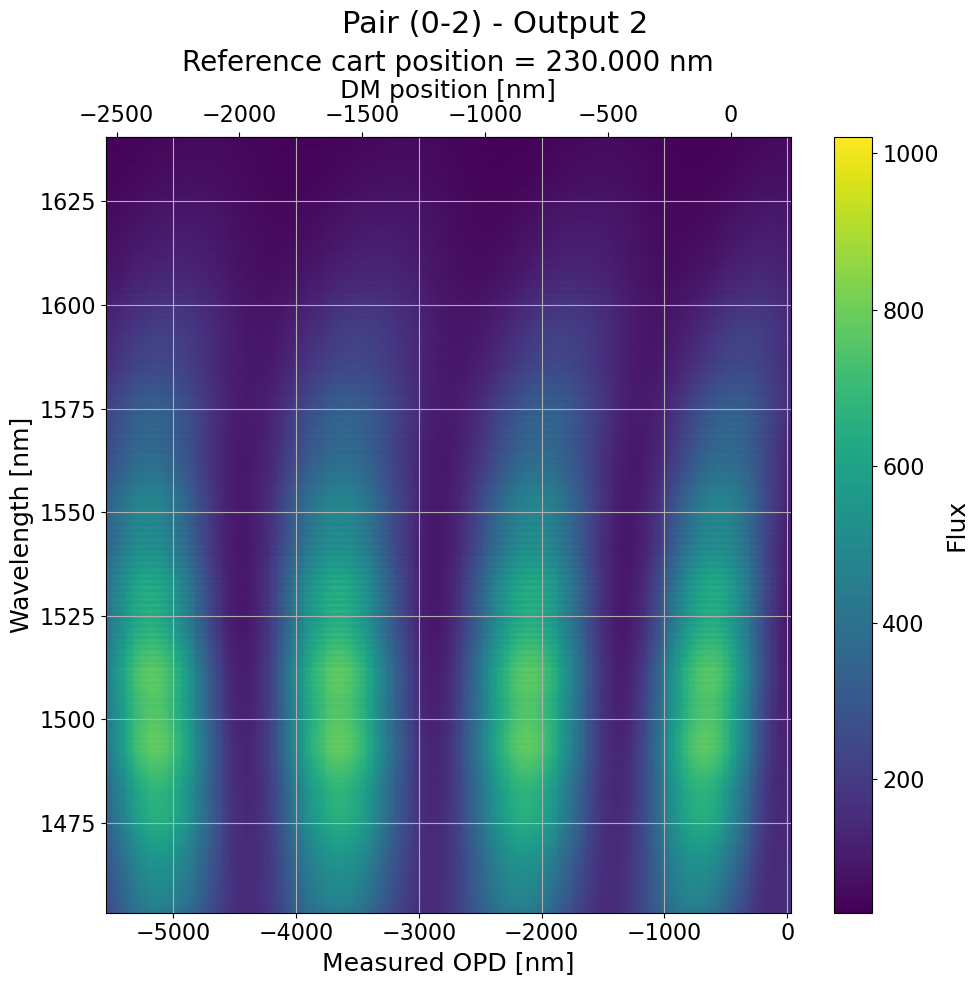

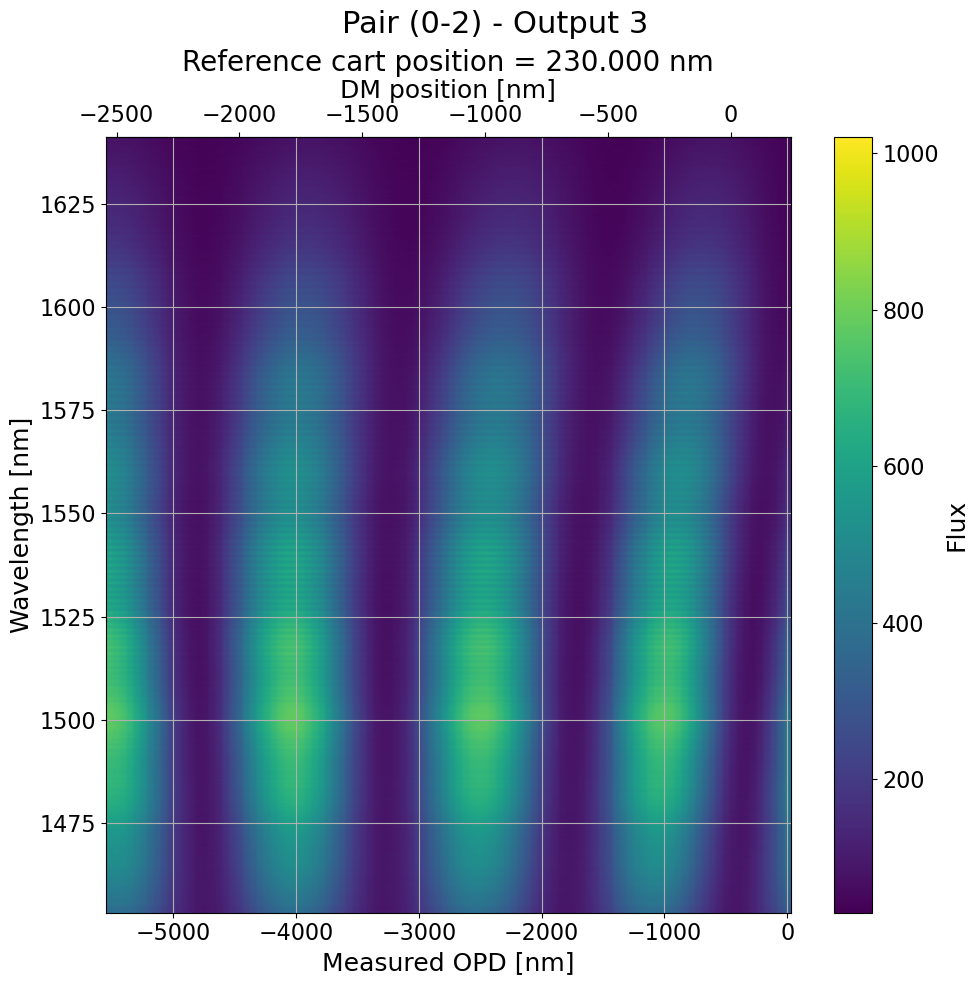

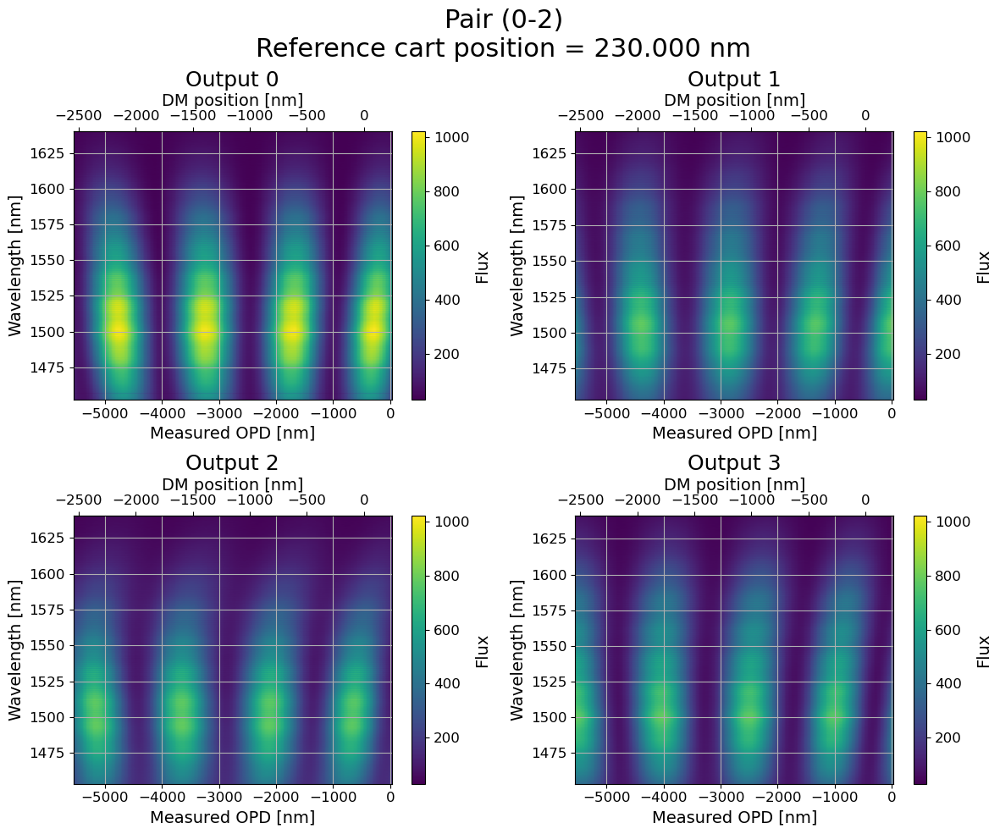

In [63]:
# Plot integrated flux
opd_step = opd_range[1] - opd_range[0]

fig, axs = plot_integrated_flux(
    opd_range=opd_range20,
    outs=outs20,
    n_roi=n_roi,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=piston_range20,
    path=path,
)

_ = plot_spectral_maps_by_output(
    opd_range=opd_range20,        # use opd_range20 in the other cell
    spectral_outs=spectral_outs20, # use spectral_outs20 in the other cell
    spectral_axs=spectral_axs,
    spec_law=spec_law,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=piston_range20,   # use piston_range20 in the other cell
    path=path,
)

_ = plot_spectral_maps_grid(
    opd_range=opd_range20,          # use opd_range20 in the other cell
    spectral_outs=spectral_outs20,  # use spectral_outs20 in the other cell
    spectral_axs=spectral_axs,
    spec_law=spec_law,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=piston_range20,    # use piston_range20 in the other cell
    path=path,
)

### Pair 0 (ref) - 3

In [86]:
ref_cart = 230
start, end = -2530, 230
# start, end = max_flux_pos - 5/8. * lam, max_flux_pos + lam / 4
spec_law = np.load(path / 'spec_cal_coeffs_and_errors.npy')[0]

pair = (0,3)
crop_mode = 'rectangles'
shapes = cam.get_outputs(flux_mode='mean', crop_mode=crop_mode).shape 
n_roi = shapes[0] - 1
spectral_sz = shapes[1]
crop_areas = np.array(phobos.Config().get('cred3.output_rectangles'))
crop_areas = crop_areas[:n_roi]
crop_areas = crop_areas[:,[0,2]] # Got the spectral bounds of each track
spectral_axs = np.array([np.arange(crop_areas[i,0], crop_areas[i,-1]) for i in range(crop_areas.shape[0])])
spectral_axs = np.array([np.polyval(spec_law[i], spectral_axs[i]) for i in range(spectral_axs.shape[0])])

outs30, spectral_outs30, bright_out30, null_out30, piston_range30, opd_range30 = scan_dm_white_light(start, end, ref_cart, nstack=10)
filename = f'opd0_dm_scan_pair_{pair[0]}-{pair[1]}_ref_{int(ref_cart)}nm_range_{int(start)}_{int(end)}nm.npz'
np.savez(path / filename, 
         data=outs30, 
         spectral_data=spectral_outs30, 
         ref_cart=ref_cart, 
         piston_range=piston_range30, 
         opd_range=opd_range30)
print('Data saved in', path / filename)


Injection OFF on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
Injection BALANCED on channels [0, 3] (segments [138, 135])


100%|██████████| 100/100 [00:02<00:00, 37.99it/s]


Max flux for output 3: -1972.4242424242425
Max flux for output 0: -1944.5454545454545
Min flux for output 3: -1582.121212121212
Min flux for output 0: -745.7575757575758
Data saved in /mnt/disk1/archive/2026-09-15_c64cfaf/1_kernel_null/opd0_dm_scan_pair_0-3_ref_230nm_range_-2530_230nm.npz


In [88]:
pair = (0,3)
# set_dm_to_white_fringe(pair, -1507, ref_cart)
set_dm_to_white_fringe(pair, null_out30[1], ref_cart)

Injection OFF on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
Injection BALANCED on channels [0, 3] (segments [138, 135])


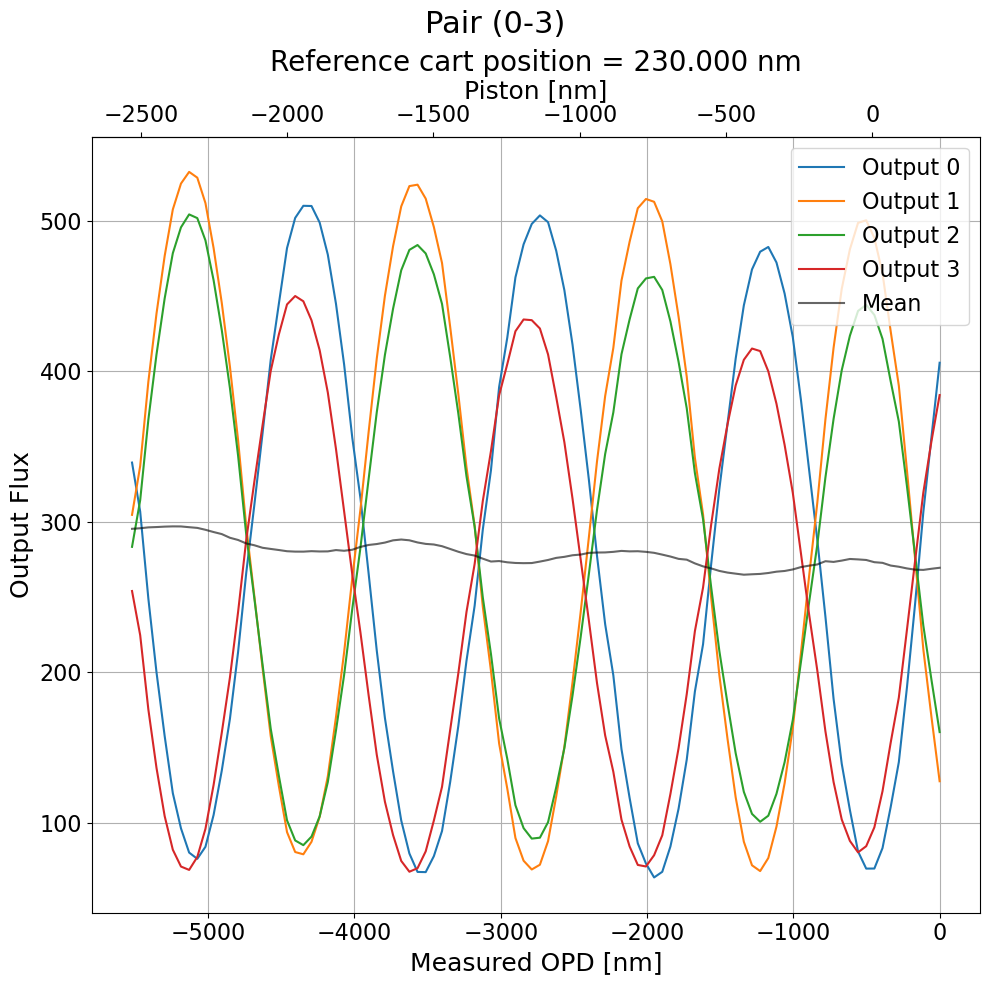

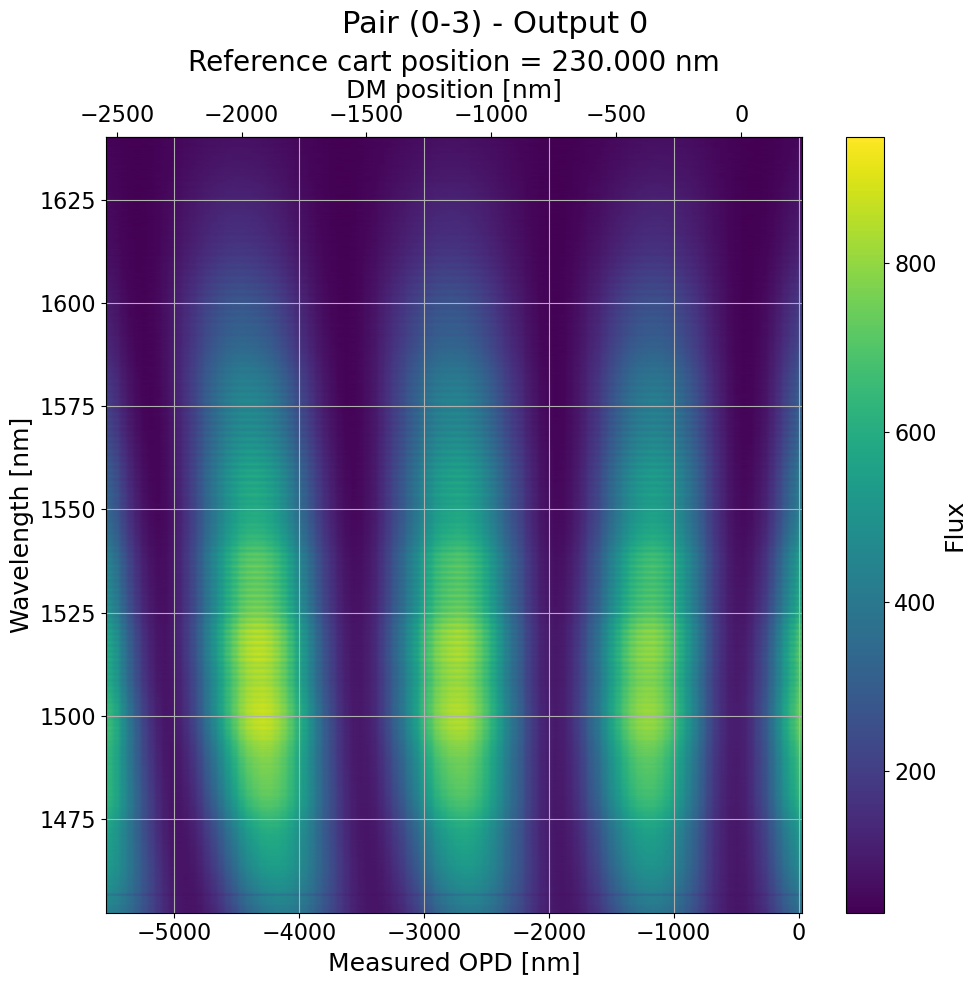

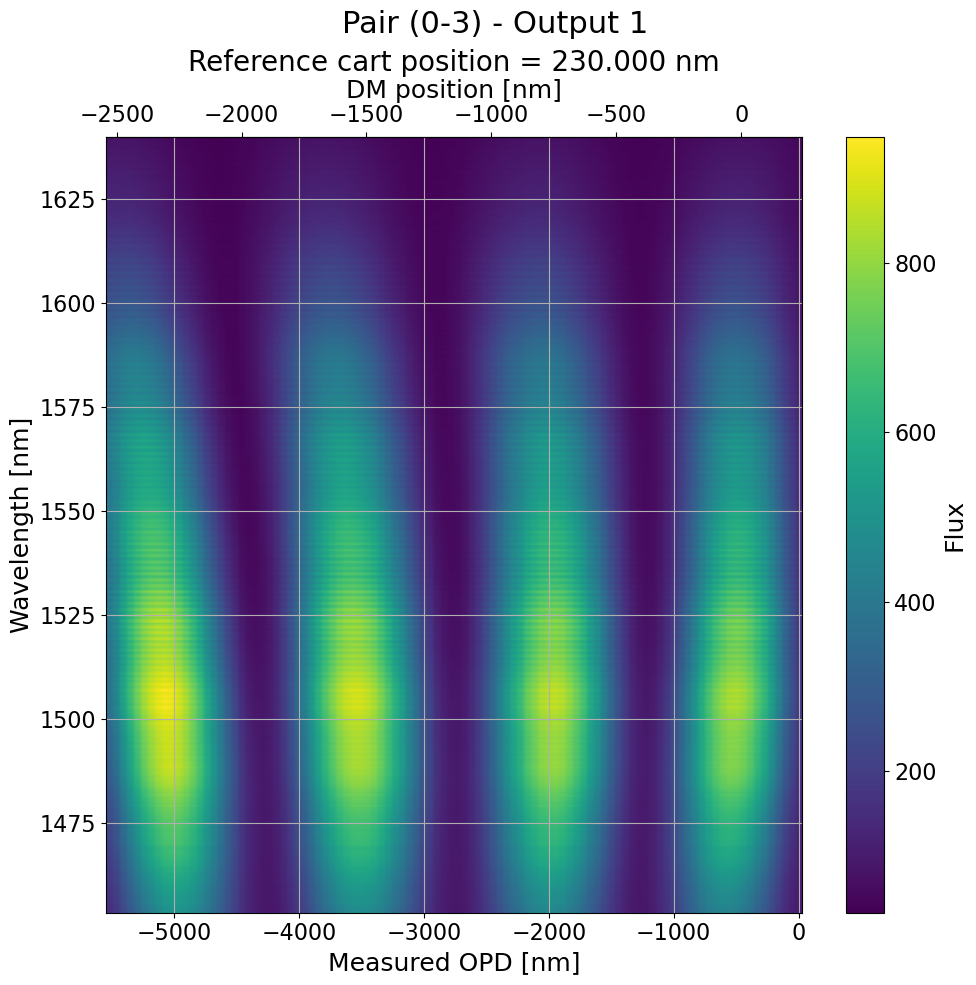

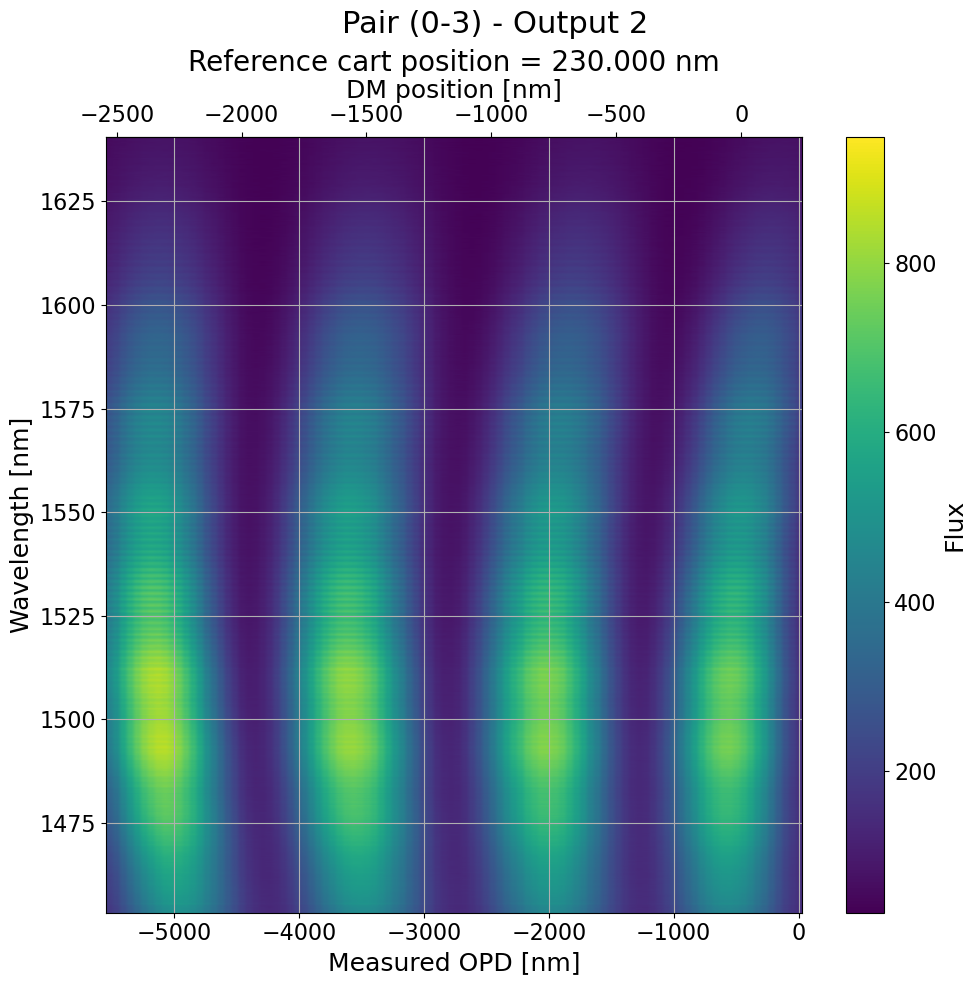

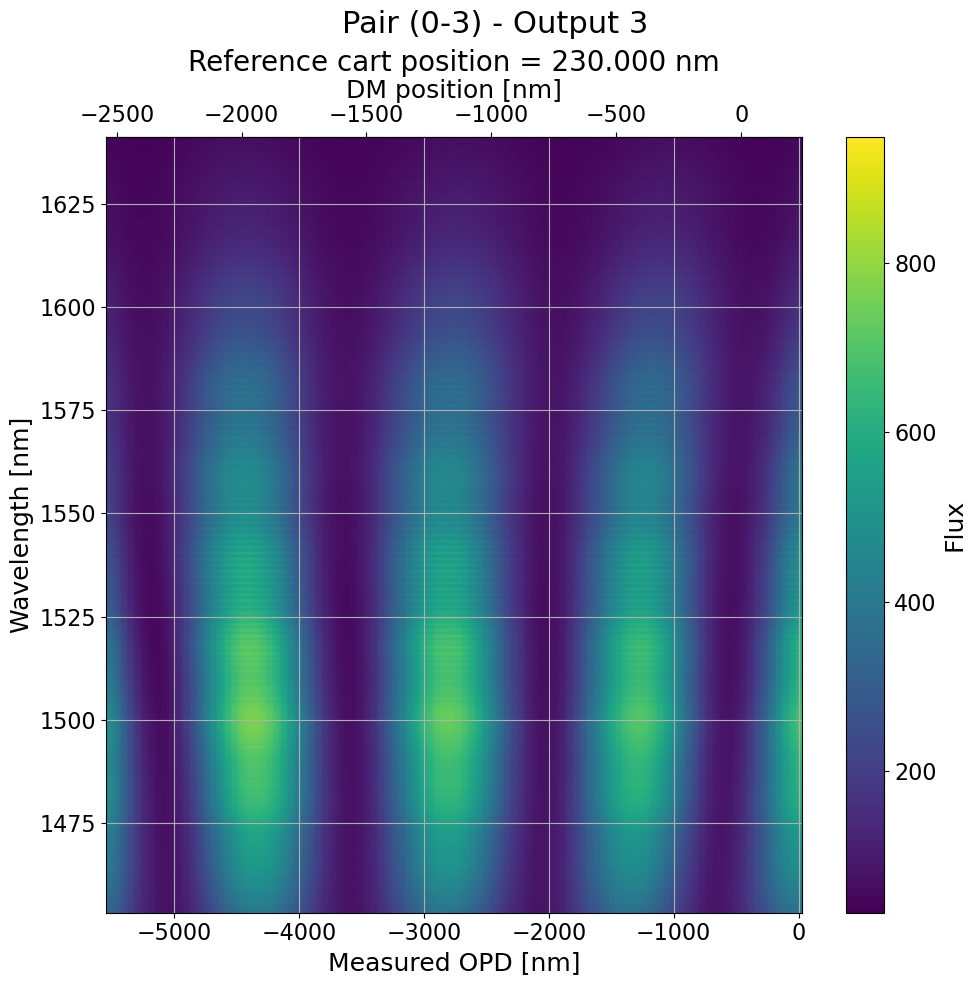

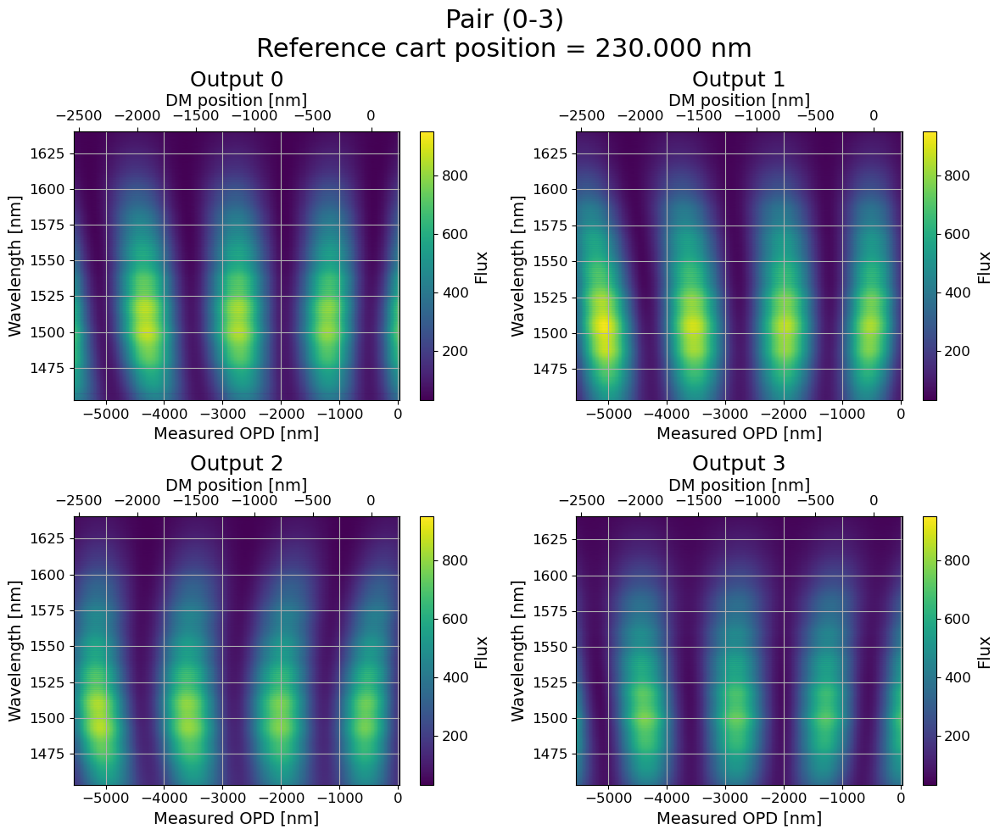

In [89]:
# Plot integrated flux
opd_step = opd_range[1] - opd_range[0]

fig, axs = plot_integrated_flux(
    opd_range=opd_range30,
    outs=outs30,
    n_roi=n_roi,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=piston_range30,
    path=path,
)

_ = plot_spectral_maps_by_output(
    opd_range=opd_range30,        # use opd_range20 in the other cell
    spectral_outs=spectral_outs30, # use spectral_outs20 in the other cell
    spectral_axs=spectral_axs,
    spec_law=spec_law,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=piston_range30,   # use piston_range20 in the other cell
    path=path,
)

_ = plot_spectral_maps_grid(
    opd_range=opd_range30,          # use opd_range20 in the other cell
    spectral_outs=spectral_outs30,  # use spectral_outs20 in the other cell
    spectral_axs=spectral_axs,
    spec_law=spec_law,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=piston_range30,    # use piston_range20 in the other cell
    path=path,
)

### Pair 0 (ref) - 1

In [92]:
ref_cart = 230
start, end = -2530, 230
# start, end = max_flux_pos - 5/8. * lam, max_flux_pos + lam / 4
spec_law = np.load(path / 'spec_cal_coeffs_and_errors.npy')[0]

pair = (0,1)
crop_mode = 'rectangles'
shapes = cam.get_outputs(flux_mode='mean', crop_mode=crop_mode).shape 
n_roi = shapes[0] - 1
spectral_sz = shapes[1]
crop_areas = np.array(phobos.Config().get('cred3.output_rectangles'))
crop_areas = crop_areas[:n_roi]
crop_areas = crop_areas[:,[0,2]] # Got the spectral bounds of each track
spectral_axs = np.array([np.arange(crop_areas[i,0], crop_areas[i,-1]) for i in range(crop_areas.shape[0])])
spectral_axs = np.array([np.polyval(spec_law[i], spectral_axs[i]) for i in range(spectral_axs.shape[0])])

outs10, spectral_outs10, bright_out10, null_out10, piston_range10, opd_range10 = scan_dm_white_light(start, end, ref_cart, nstack=10)
filename = f'opd0_dm_scan_pair_{pair[0]}-{pair[1]}_ref_{int(ref_cart)}nm_range_{int(start)}_{int(end)}nm.npz'
np.savez(path / filename, 
         data=outs10, 
         spectral_data=spectral_outs10, 
         ref_cart=ref_cart, 
         piston_range=piston_range10, 
         opd_range=opd_range10)
print('Data saved in', path / filename)


Injection OFF on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
Injection BALANCED on channels [0, 1] (segments [138, 137])


  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:02<00:00, 39.24it/s]


Max flux for output 3: -2279.090909090909
Max flux for output 0: -1888.7878787878788
Min flux for output 3: -1888.7878787878788
Min flux for output 0: -2251.212121212121
Data saved in /mnt/disk1/archive/2026-09-15_c64cfaf/1_kernel_null/opd0_dm_scan_pair_0-1_ref_230nm_range_-2530_230nm.npz


In [96]:
pair = (0,1)
# set_dm_to_white_fringe(pair, -1507, ref_cart)
set_dm_to_white_fringe(pair, null_out10[1], ref_cart)

Injection OFF on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
Injection BALANCED on channels [0, 1] (segments [138, 137])


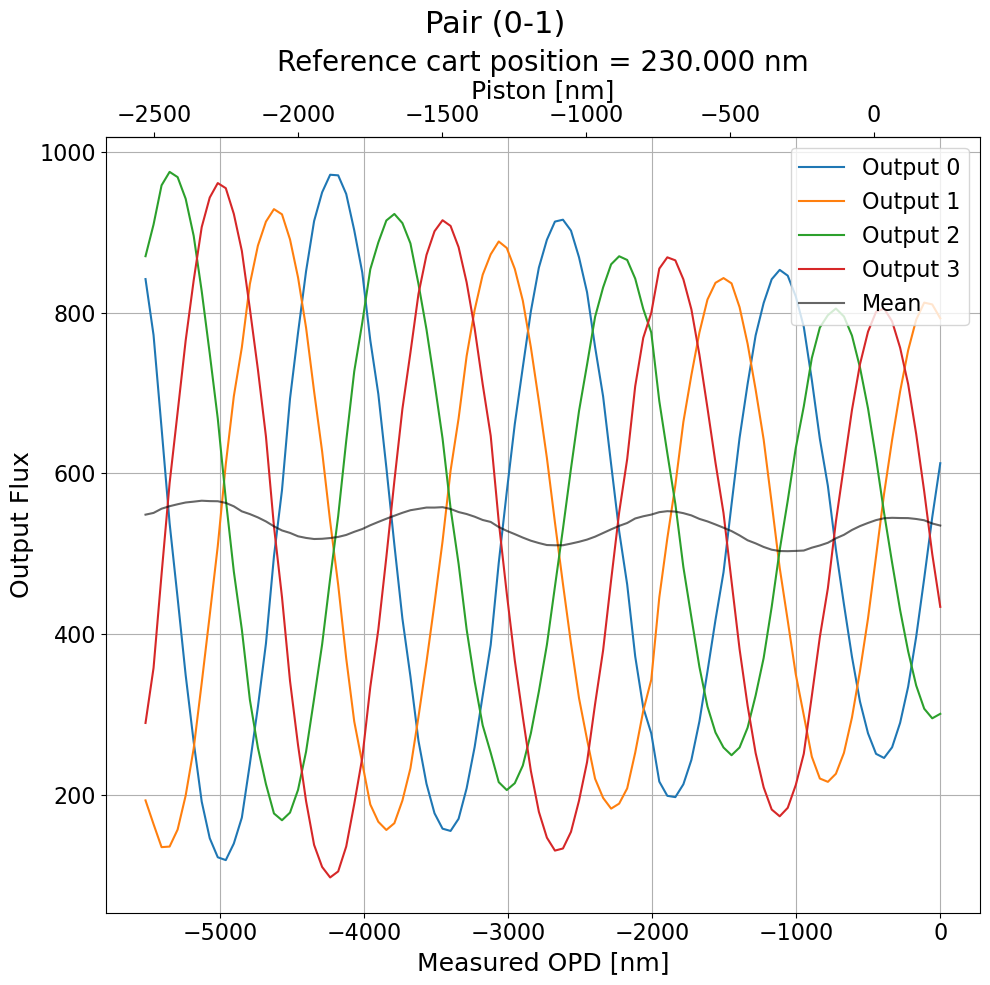

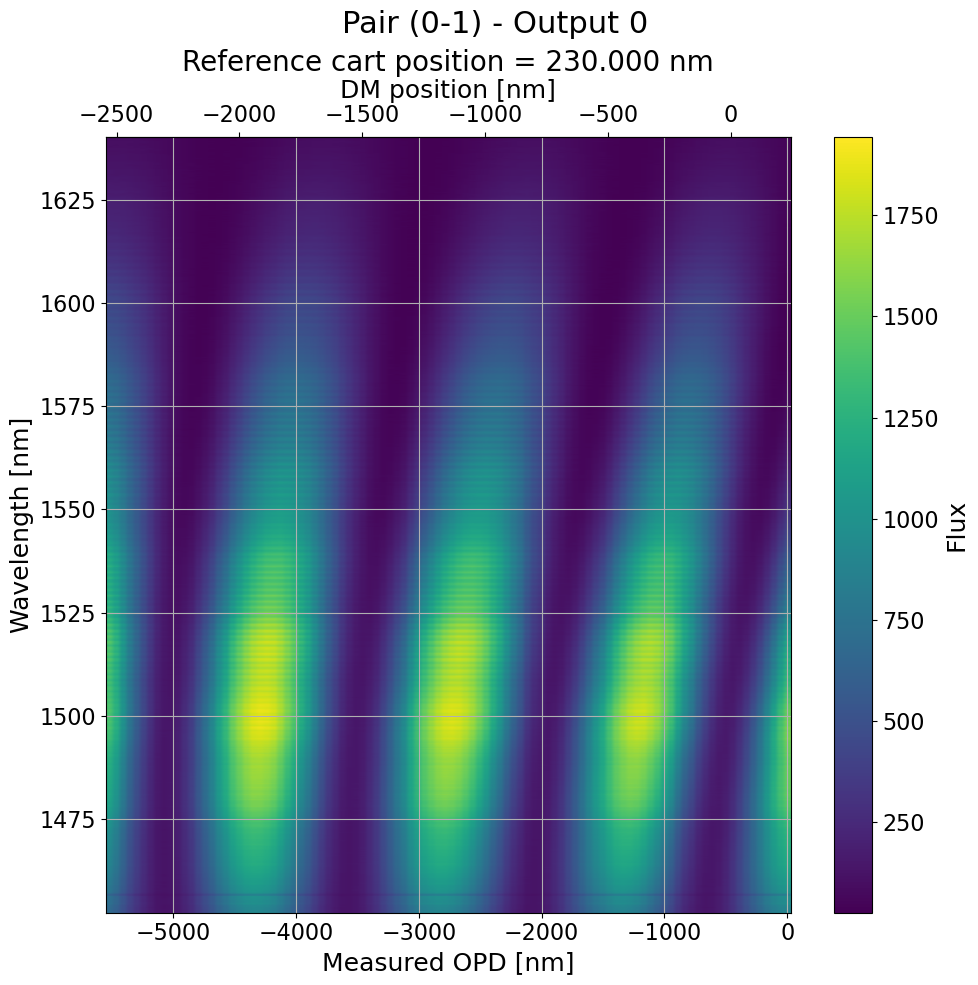

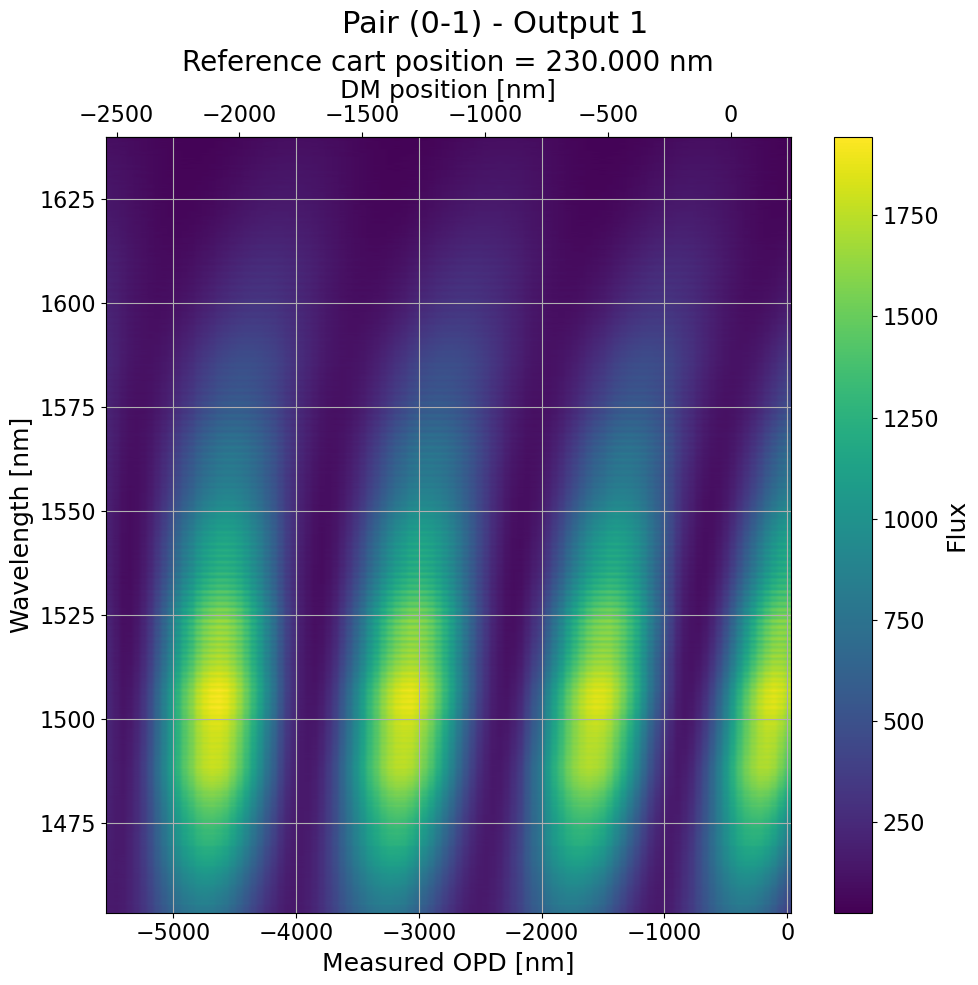

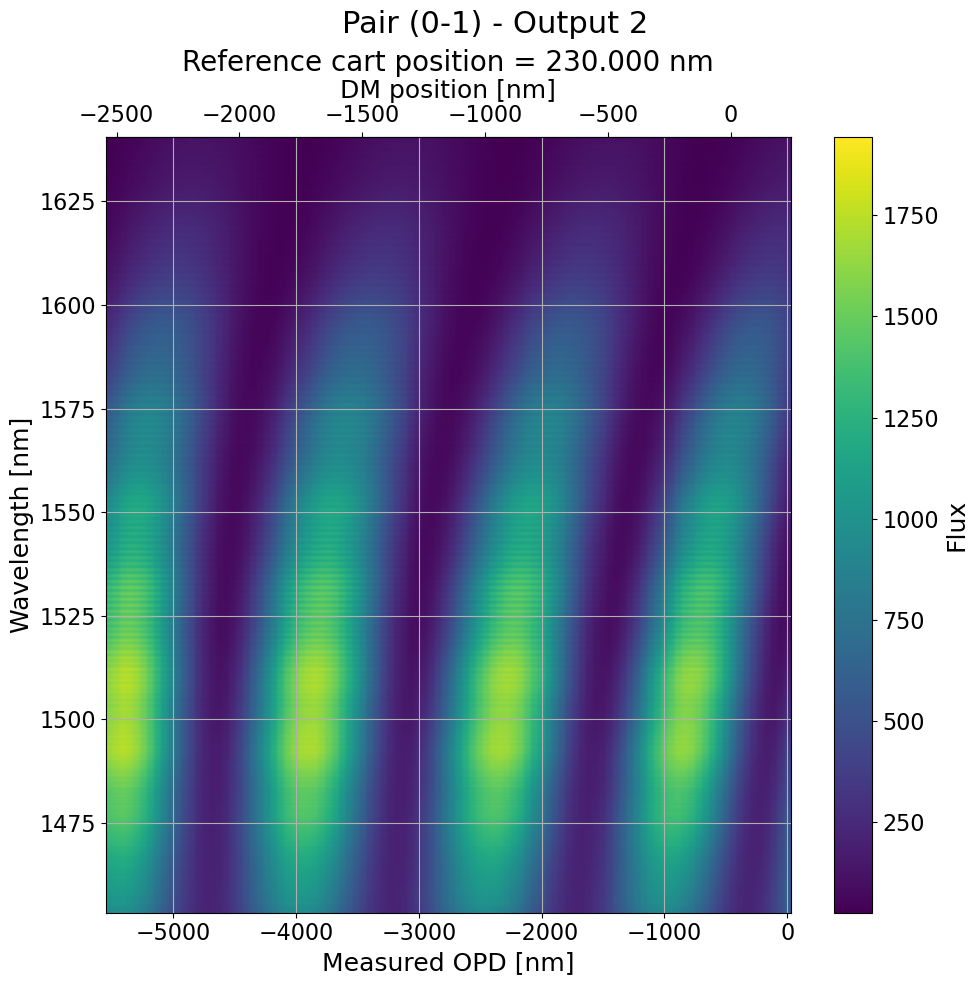

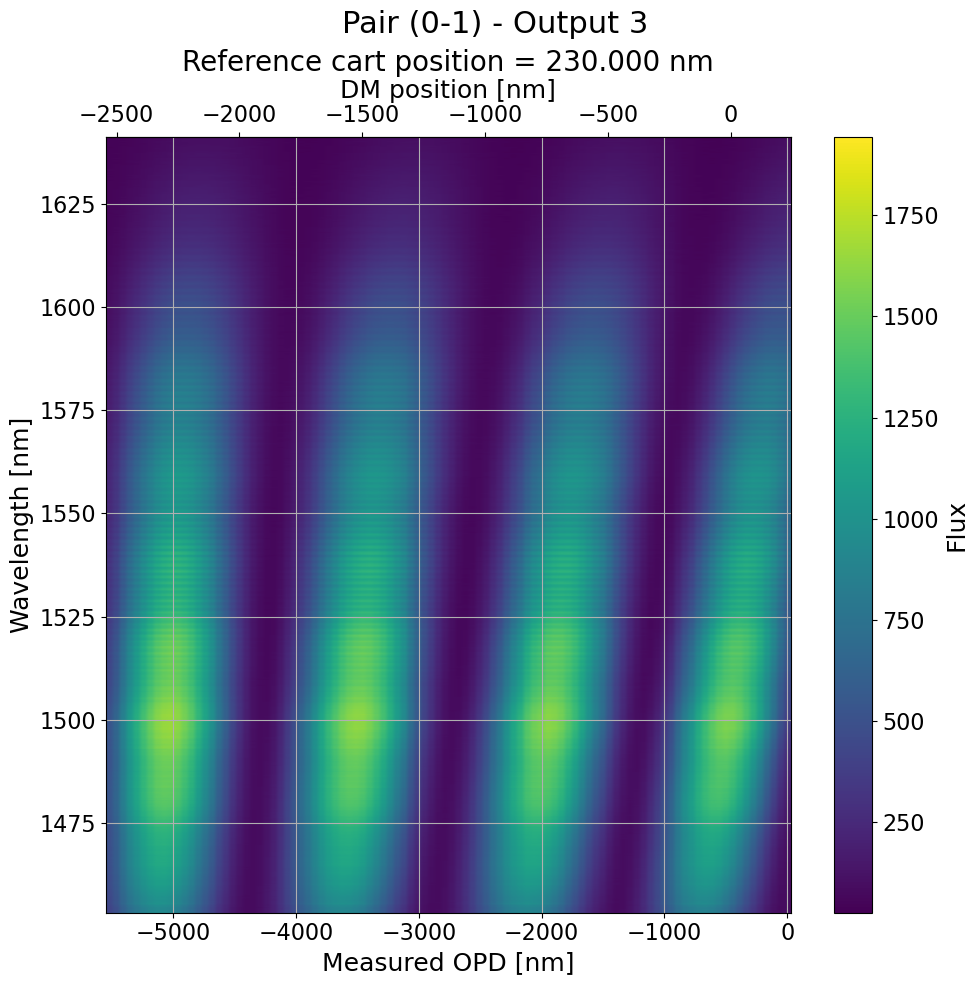

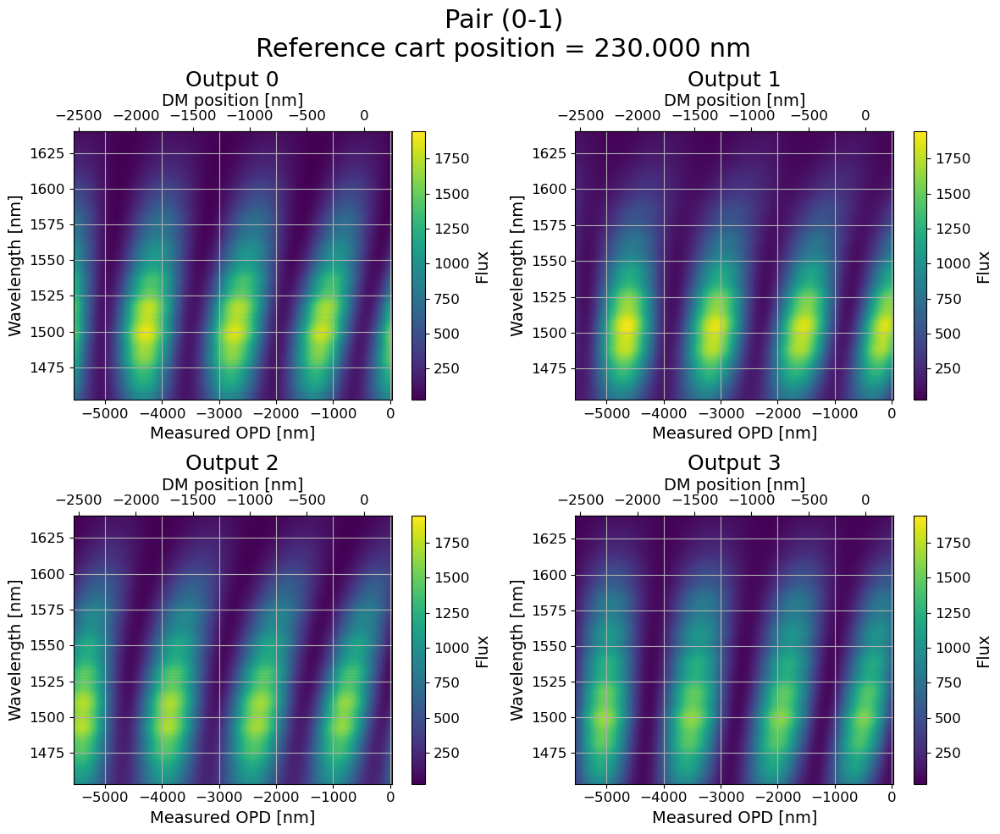

In [95]:
# Plot integrated flux
opd_step = opd_range[1] - opd_range[0]

fig, axs = plot_integrated_flux(
    opd_range=opd_range10,
    outs=outs10,
    n_roi=n_roi,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=piston_range10,
    path=path,
)

_ = plot_spectral_maps_by_output(
    opd_range=opd_range10,        # use opd_range20 in the other cell
    spectral_outs=spectral_outs10, # use spectral_outs20 in the other cell
    spectral_axs=spectral_axs,
    spec_law=spec_law,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=piston_range10,   # use piston_range20 in the other cell
    path=path,
)

_ = plot_spectral_maps_grid(
    opd_range=opd_range10,          # use opd_range20 in the other cell
    spectral_outs=spectral_outs10,  # use spectral_outs20 in the other cell
    spectral_axs=spectral_axs,
    spec_law=spec_law,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=piston_range10,    # use piston_range20 in the other cell
    path=path,
)

# Scanning the 3 mirors at 4 beams

In [ ]:
inj.set_balanced()

bounds_p1_low = max(-2530, null_out10[1]-lam/2/2)
bounds_p1_high = min(230, bounds_p1_low + lam/2)

bounds_p2_low = max(-2530, null_out20[1]-lam/2/2)
bounds_p2_high = min(230, bounds_p2_low + lam/2)

bounds_p3_low = max(-2530, null_out30[1]-lam/2/2)
bounds_p3_high = min(230, bounds_p3_low + lam/2)

nsamp = 30
piston_range_p1 = np.linspace(bounds_p1_low, bounds_p1_high, nsamp, endpoint=False)
piston_range_p2 = np.linspace(bounds_p2_low, bounds_p2_high, nsamp, endpoint=False)
piston_range_p3 = np.linspace(bounds_p3_low, bounds_p3_high, nsamp, endpoint=False)
ref_tip = [dm[elt].get_tip() for elt in inj_seg]
ref_tilt = [dm[elt].get_tilt() for elt in inj_seg]
nstack = 10
crop_mode = 'rectangles'

ref_cart = 230
dm[inj_seg[0]].set_ptt(ref_cart, ref_tip[0], ref_tilt[0])

datacube = []

for p1 in tqdm(piston_range_p1): # iterate over inj_seg[1] = 137
    temp1 = []
    for p2 in piston_range_p2: # iterate over inj_seg[2] = 136
        temp2 = []
        for p3 in piston_range_p3: # iterate over inj_seg[3] = 135
            dm[inj_seg[1]].set_ptt(p1, ref_tip[1], ref_tilt[1])
            dm[inj_seg[2]].set_ptt(p2, ref_tip[2], ref_tilt[2])
            dm[inj_seg[3]].set_ptt(p3, ref_tip[3], ref_tilt[3])
            img = cam.get_outputs(stack=nstack, crop_mode=crop_mode)
            temp2.append(img)
        temp1.append(temp2)
    datacube.append(temp1)

datacube = np.array(datacube)
np.savez(path / f'dm_scan_kernel_4x4_datacube_refcart_{ref_cart}_4T.npz', data=datacube, piston_range_p1=piston_range_p1, piston_range_p2=piston_range_p2, piston_range_p3=piston_range_p3)


Injection BALANCED on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])


100%|██████████| 30/30 [10:14<00:00, 20.48s/it]


In [102]:
# 2T scans
pair = (0, 3)
inj.off()
inj.set_balanced(pair)
ref_tip = [dm[elt].get_tip() for elt in inj_seg]
ref_tilt = [dm[elt].get_tilt() for elt in inj_seg]
ref_piston = [dm[elt].get_piston() for elt in inj_seg]

start, end = -1130, -300
nsamp = 30

if 1 in pair:
    piston_range_p1 = np.linspace(bounds_p1_low, bounds_p1_high, nsamp)
else:
    piston_range_p1 = [ref_piston[1]]

if 2 in pair:
    piston_range_p2 = np.linspace(bounds_p2_low, bounds_p2_high, nsamp)
else:
    piston_range_p2 = [ref_piston[2]]

if 3 in pair:
    piston_range_p3 = np.linspace(bounds_p3_low, bounds_p3_high, nsamp)
else:
    piston_range_p3 = [ref_piston[3]]

nstack = 10
crop_mode = 'rectangles'

ref_cart = 230
dm[inj_seg[0]].set_ptt(ref_cart, ref_tip[0], ref_tilt[0])
img = cam.get_outputs(stack=nstack, crop_mode=crop_mode)

datacube = []

for p1 in piston_range_p1: # iterate over inj_seg[1] = 137
    temp1 = []
    for p2 in piston_range_p2: # iterate over inj_seg[2] = 136
        temp2 = []
        for p3 in piston_range_p3: # iterate over inj_seg[3] = 135
            dm[inj_seg[1]].set_ptt(p1, ref_tip[1], ref_tilt[1])
            dm[inj_seg[2]].set_ptt(p2, ref_tip[2], ref_tilt[2])
            dm[inj_seg[3]].set_ptt(p3, ref_tip[3], ref_tilt[3])
            img = cam.get_outputs(stack=nstack, crop_mode=crop_mode)
            temp2.append(img)
        temp1.append(temp2)
    datacube.append(temp1)

datacube = np.array(datacube)
np.savez(path / f'dm_scan_kernel_4x4_datacube_refcart_{ref_cart}_2T_pair_{pair[0]}-{pair[1]}.npz', data=datacube, piston_range_p1=piston_range_p1, piston_range_p2=piston_range_p2, piston_range_p3=piston_range_p3)


Injection OFF on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
Injection BALANCED on channels [0, 3] (segments [138, 135])


# TOPs: scanning the three TOPs around white fringe

In [73]:
def scan_topa_white_fringe(start, end, nstack, ref_cart, dm_pos):
    inj.off()
    inj.set_balanced(np.array(pair))

    ref_tip = (dm[inj_seg[pair[0]]].get_tip(), dm[inj_seg[pair[1]]].get_tip())
    ref_tilt = (dm[inj_seg[pair[0]]].get_tilt(), dm[inj_seg[pair[1]]].get_tilt())

    dm[inj_seg[pair[1]]].set_ptt(ref_cart, ref_tip[1], ref_tilt[1])
    dm[inj_seg[pair[0]]].set_ptt(dm_pos, ref_tip[0], ref_tilt[0])

    power_ramp = np.linspace(start, end, 100, endpoint=True)

    # Scan on first input
    outs = np.empty((len(power_ramp), n_roi))
    spectral_outs = np.empty((len(power_ramp), n_roi, spectral_sz))
    for p, power in enumerate(tqdm(power_ramp)):
        powers = np.zeros((len(chip.shifters),))
        powers[pair[0]] = power
        chip.set_powers(powers)
        if p == 0:
            time.sleep(0.1)
        frame = cam.get_outputs(flux_mode='mean', crop_mode=crop_mode, stack=nstack)[:n_roi]
        outs[p] = frame.mean(1)
        spectral_outs[p] = frame

    chip.turn_off()
    time.sleep(0.1)

    max_flux_pos3 = power_ramp[np.argmax(outs[:,3])]
    max_flux_pos0 = power_ramp[np.argmax(outs[:,0])]
    max_flux_pos1 = power_ramp[np.argmax(outs[:,1])]
    max_flux_pos2 = power_ramp[np.argmax(outs[:,2])]
    print('TOPA Max flux for output 3:', max_flux_pos3)
    print('TOPA Max flux for output 0:', max_flux_pos0)
    print('TOPA Max flux for output 1:', max_flux_pos1)
    print('TOPA Max flux for output 2:', max_flux_pos2)

    return outs, spectral_outs, (max_flux_pos3, max_flux_pos0, max_flux_pos1, max_flux_pos2), power_ramp

def set_topa_to_white_fringe(pair, pow, ref_cart, dm_pos):
    inj.off()
    inj.set_balanced(np.array(pair))

    ref_tip = (dm[inj_seg[pair[0]]].get_tip(), dm[inj_seg[pair[1]]].get_tip())
    ref_tilt = (dm[inj_seg[pair[0]]].get_tilt(), dm[inj_seg[pair[1]]].get_tilt())

    dm[inj_seg[pair[1]]].set_ptt(ref_cart, ref_tip[1], ref_tilt[1])
    dm[inj_seg[pair[0]]].set_ptt(dm_pos, ref_tip[0], ref_tilt[0])

    powers = np.zeros((len(chip.shifters),))
    powers[pair[0]] = pow
    chip.set_powers(powers)

## Pair 2-0

In [67]:
ref_cart = 230
dm_pos = max_flux_pos20[1]
start, end = 0., 1.
nbframes = 10
spec_law = np.load(path / 'spec_cal_coeffs_and_errors.npy')[0]

pair = (2,0)
crop_mode = 'rectangles'
shapes = cam.get_outputs(flux_mode='mean', crop_mode=crop_mode).shape 
n_roi = shapes[0] - 1
spectral_sz = shapes[1]
crop_areas = np.array(phobos.Config().get('cred3.output_rectangles'))
crop_areas = crop_areas[:n_roi]
crop_areas = crop_areas[:,[0,2]] # Got the spectral bounds of each track
spectral_axs = np.array([np.arange(crop_areas[i,0], crop_areas[i,-1]) for i in range(crop_areas.shape[0])])
spectral_axs = np.array([np.polyval(spec_law[i], spectral_axs[i]) for i in range(spectral_axs.shape[0])])

outs20t, spectral_outs20t, max_flux_pos20t, power_ramp20t = scan_topa_white_fringe(start, end, nbframes, ref_cart, dm_pos)

chip.turn_off()

filename = f'opd0_topa_scan_pair_{pair[0]}-{pair[1]}_ref_{int(ref_cart)}-{int(dm_pos)}_nm_range_{int(start)}_{int(end)}W.npz'
np.savez(path / filename, 
         data=outs20t, 
         spectral_data=spectral_outs20t, 
         ref_cart=ref_cart, 
         power_ramp=power_ramp20t, 
         )
print('Data saved in', path / filename)

Injection OFF on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
Injection BALANCED on channels [2, 0] (segments [136, 138])


  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:12<00:00,  8.24it/s]


TOPA Max flux for output 3: 0.27272727272727276
TOPA Max flux for output 0: 0.010101010101010102
Data saved in /mnt/disk1/archive/2026-06-30_75b9dd8/4_2T_hypercube/opd0_topa_scan_pair_2-0_ref_230--1130_nm_range_0_1W.npz


In [68]:
set_topa_to_white_fringe(pair, max_flux_pos20t[0], ref_cart, dm_pos)


Injection OFF on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
Injection BALANCED on channels [2, 0] (segments [136, 138])


In [69]:
chip.turn_off()

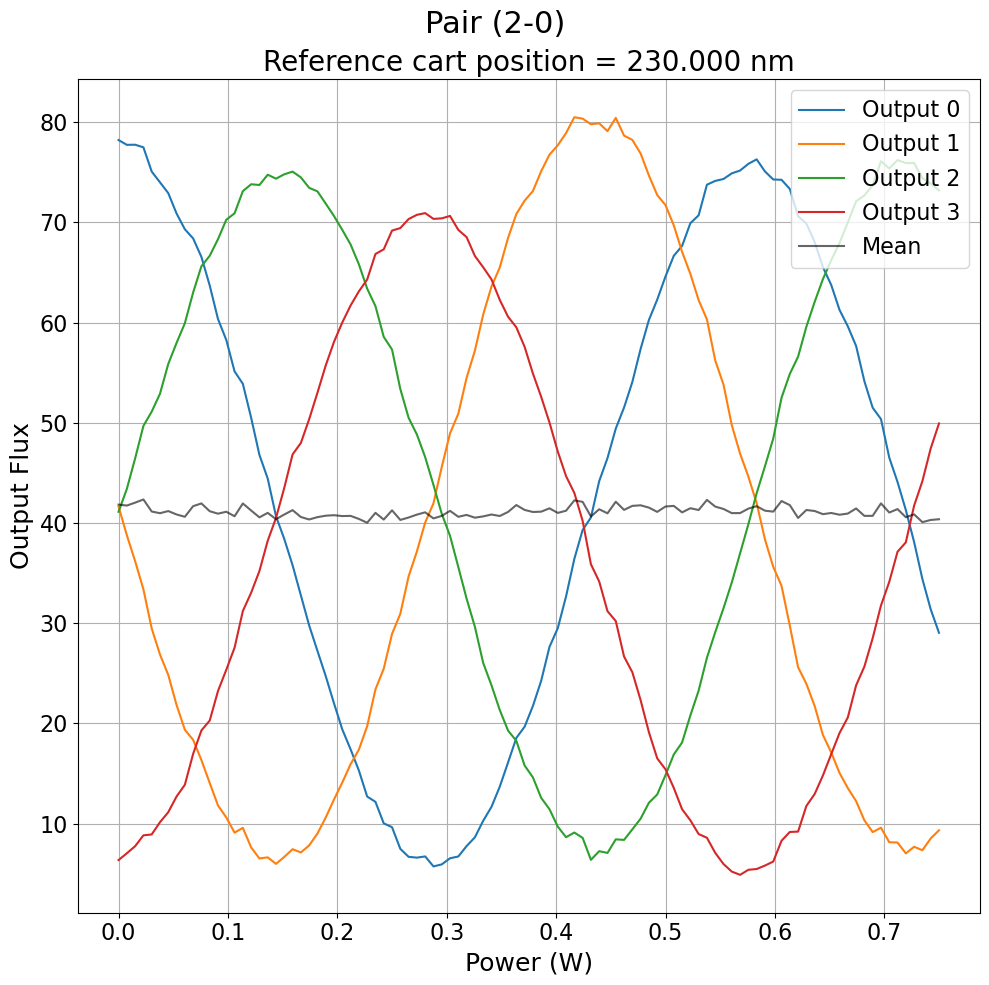

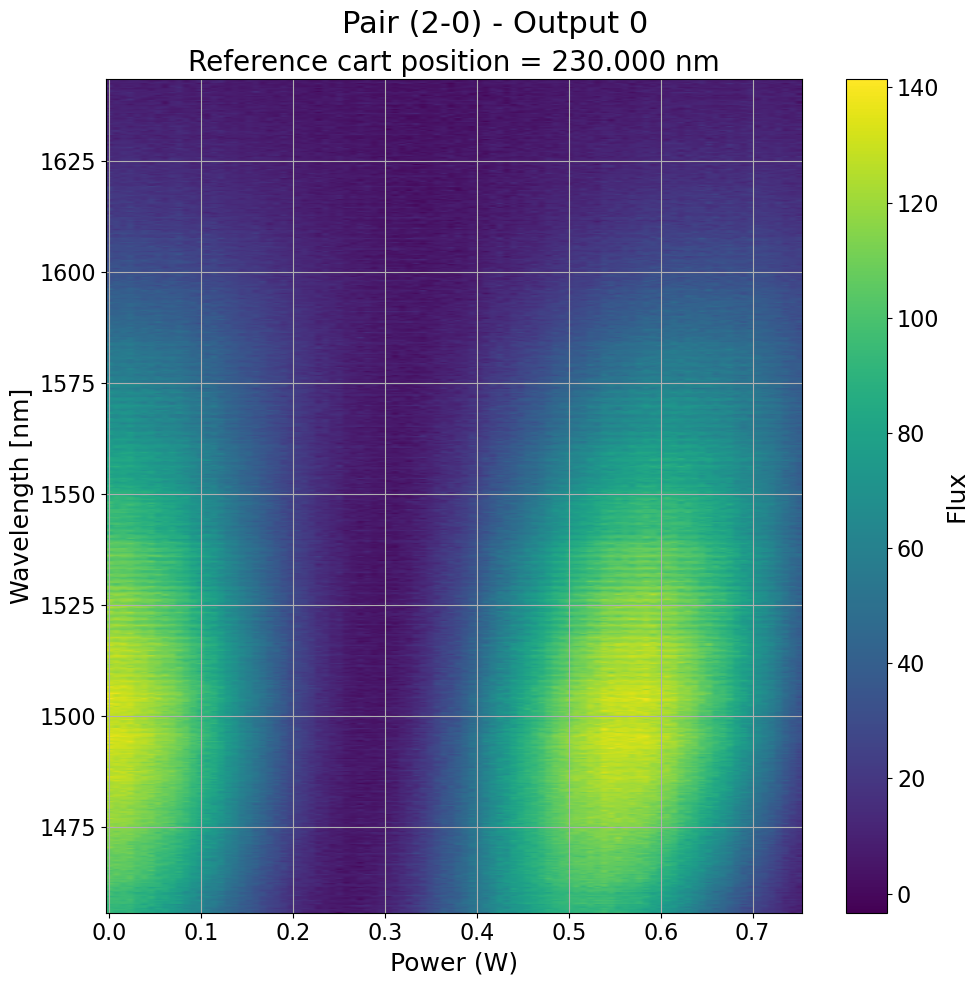

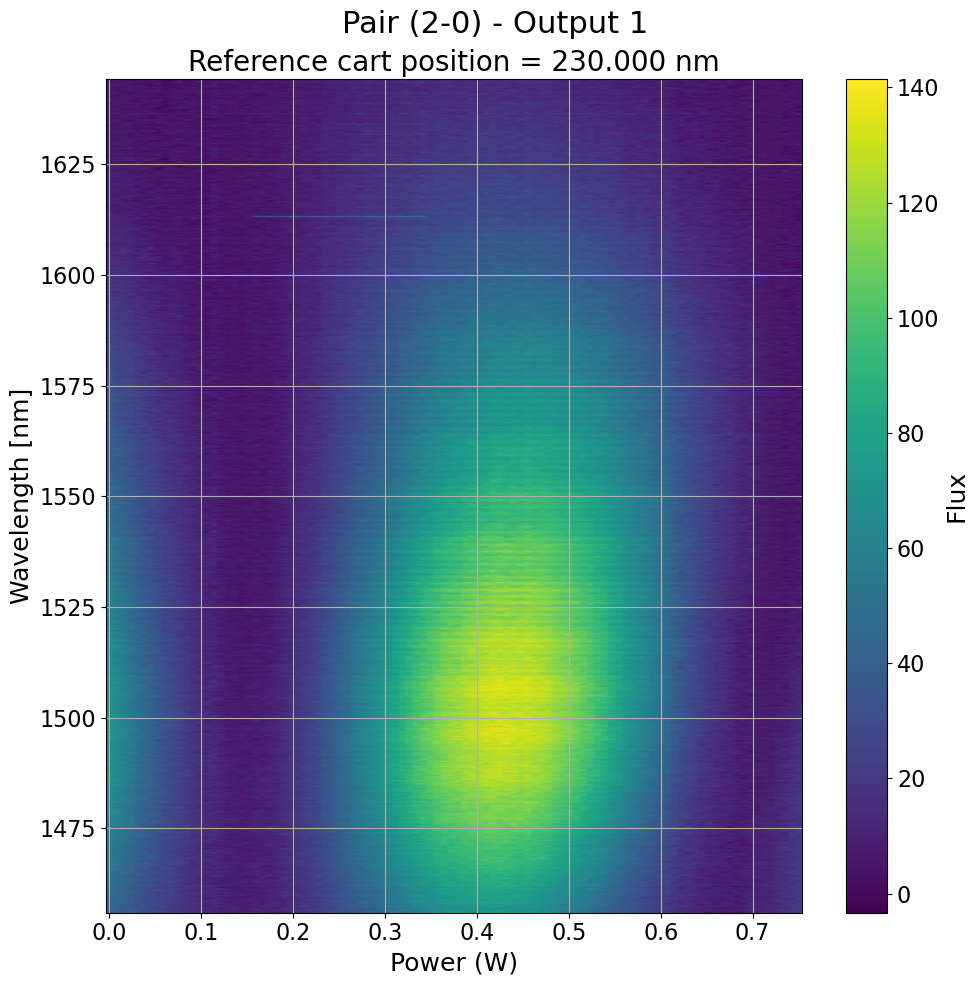

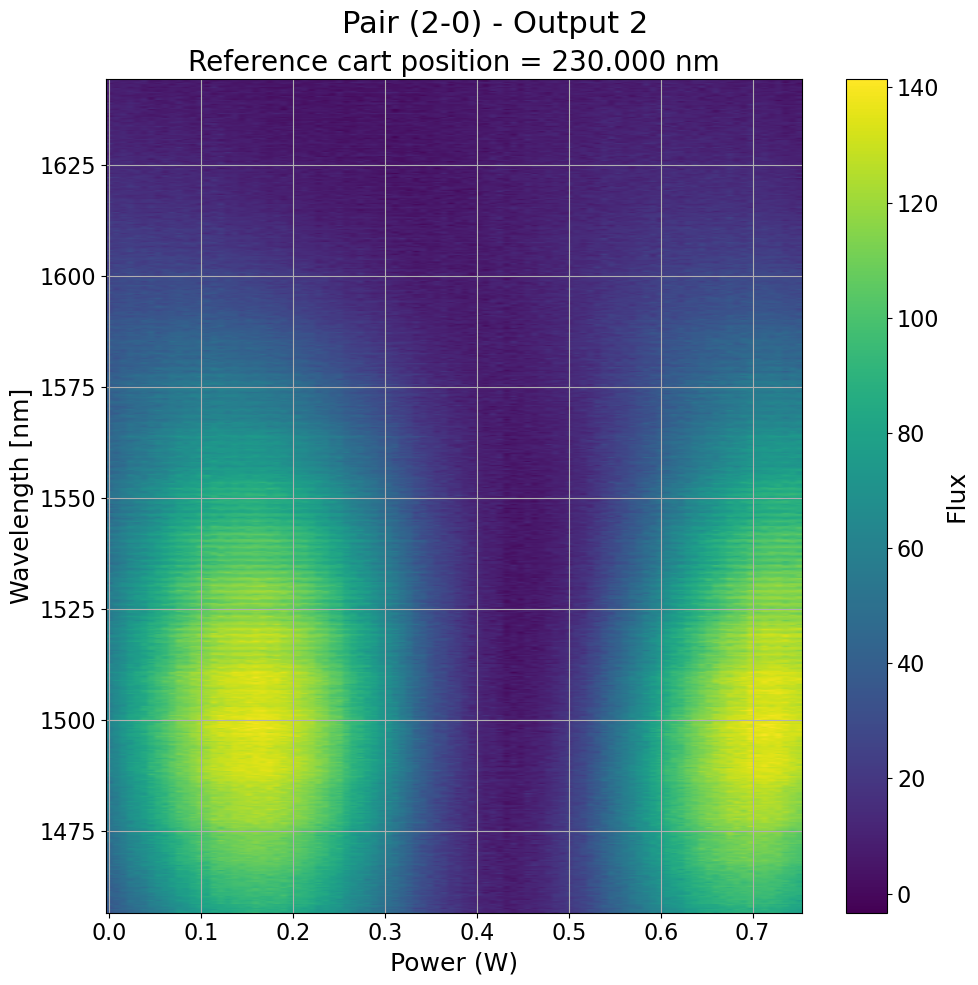

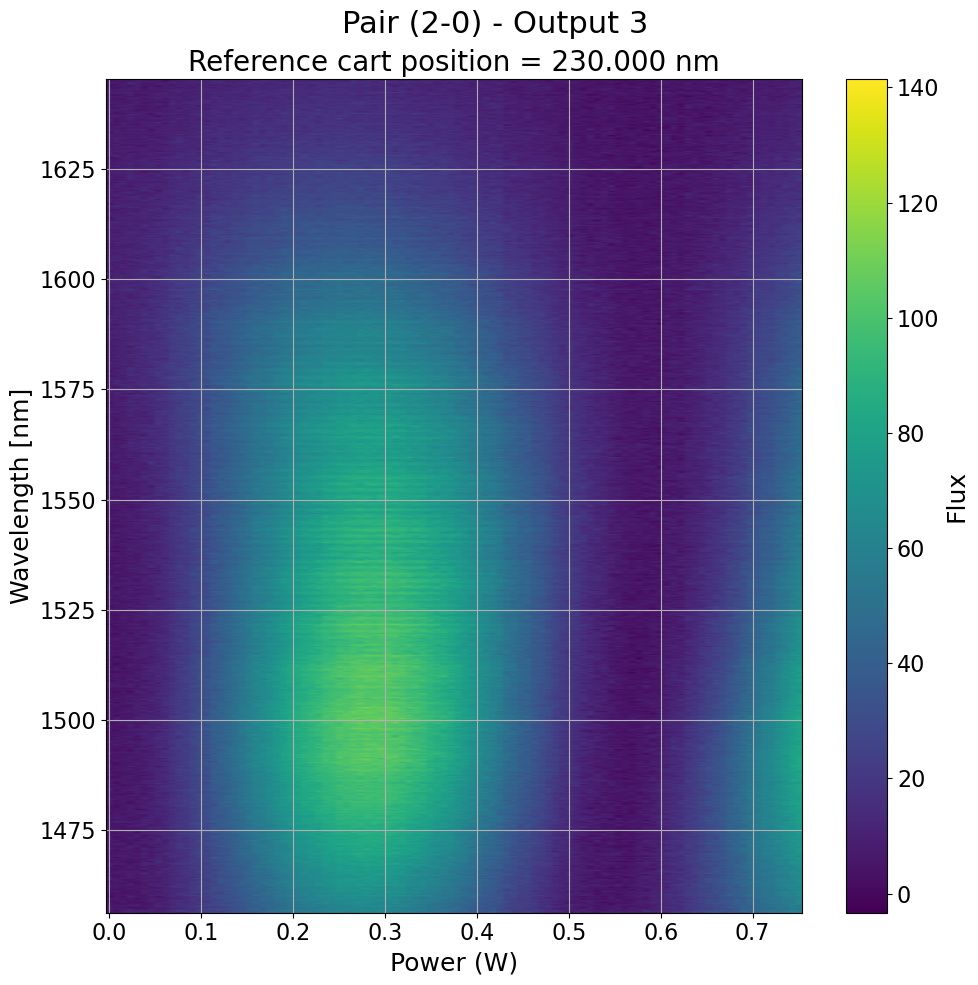

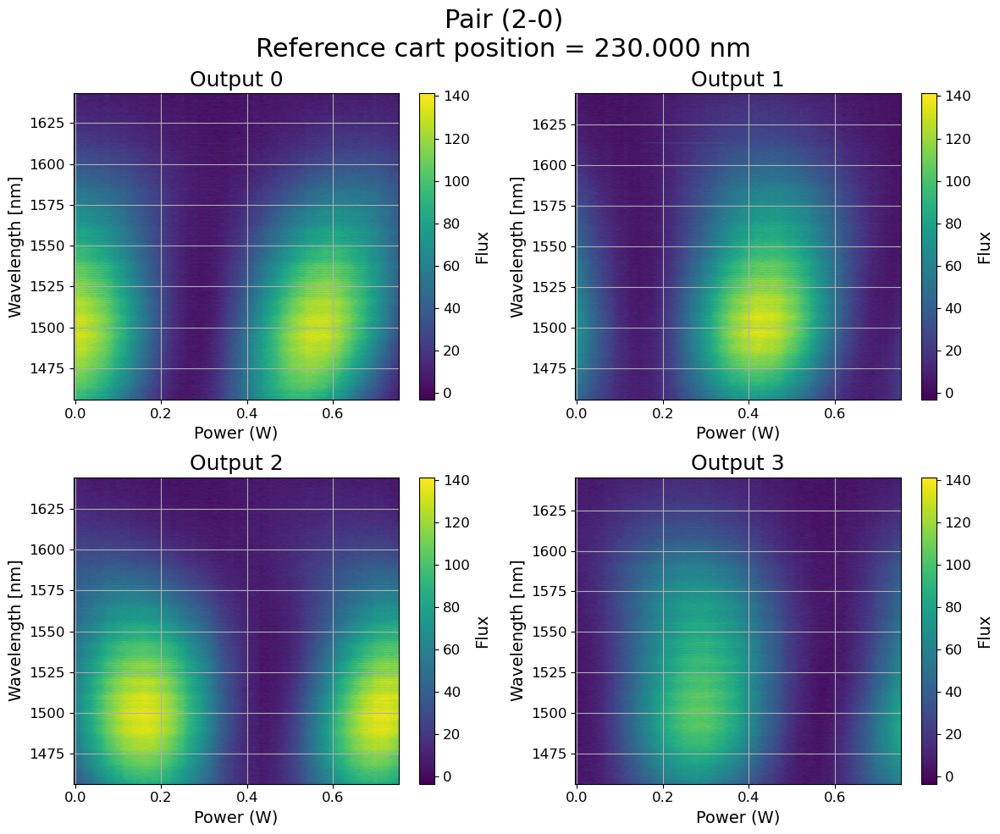

In [40]:
# Plot integrated flux
opd_step = power_ramp20t[1] - power_ramp20t[0]

fig, axs = plot_integrated_flux(
    opd_range=power_ramp20t,
    outs=outs20t,
    n_roi=n_roi,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=power_ramp20t,
    path=path,
    filename_prefix='opd0_topa_scan_pair',
    xlabel = 'Power (W)',
    sec_axis = False
)

_ = plot_spectral_maps_by_output(
    opd_range=power_ramp20t,        # use opd_range20 in the other cell
    spectral_outs=spectral_outs20t, # use spectral_outs20 in the other cell
    spectral_axs=spectral_axs,
    spec_law=spec_law,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=power_ramp20t,   # use piston_range20 in the other cell
    path=path,
    filename_prefix='opd0_topa_scan_pair',
    xlabel = 'Power (W)',
    sec_axis = False   
)

_ = plot_spectral_maps_grid(
    opd_range=power_ramp20t,          # use opd_range20 in the other cell
    spectral_outs=spectral_outs20t,  # use spectral_outs20 in the other cell
    spectral_axs=spectral_axs,
    spec_law=spec_law,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=power_ramp20t,    # use piston_range20 in the other cell
    path=path,
    filename_prefix='opd0_topa_scan_pair',
    xlabel = 'Power (W)',
    sec_axis = False
)

## Pair 3-0

In [74]:
ref_cart = 230
dm_pos = max_flux_pos30[0] + lam / 4.
start, end = 0., 1.
nbframes = 10
spec_law = np.load(path / 'spec_cal_coeffs_and_errors.npy')[0]

pair = (3,0)
crop_mode = 'rectangles'
shapes = cam.get_outputs(flux_mode='mean', crop_mode=crop_mode).shape 
n_roi = shapes[0] - 1
spectral_sz = shapes[1]
crop_areas = np.array(phobos.Config().get('cred3.output_rectangles'))
crop_areas = crop_areas[:n_roi]
crop_areas = crop_areas[:,[0,2]] # Got the spectral bounds of each track
spectral_axs = np.array([np.arange(crop_areas[i,0], crop_areas[i,-1]) for i in range(crop_areas.shape[0])])
spectral_axs = np.array([np.polyval(spec_law[i], spectral_axs[i]) for i in range(spectral_axs.shape[0])])

outs30t, spectral_outs30t, max_flux_pos30t, power_ramp30t = scan_topa_white_fringe(start, end, nbframes, ref_cart, dm_pos)
filename = f'opd0_topa_scan_pair_{pair[0]}-{pair[1]}_ref_{int(ref_cart)}-{int(dm_pos)}nm_range_{int(start)}_{int(end)}W.npz'
np.savez(path / filename, 
         data=outs30t, 
         spectral_data=spectral_outs30t, 
         ref_cart=ref_cart, 
         power_ramp=power_ramp30t, 
         )
print('Data saved in', path / filename)

Injection OFF on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
Injection BALANCED on channels [3, 0] (segments [135, 138])


100%|██████████| 100/100 [00:12<00:00,  8.16it/s]


TOPA Max flux for output 3: 0.2828282828282829
TOPA Max flux for output 0: 0.2828282828282829
TOPA Max flux for output 1: 0.0
TOPA Max flux for output 2: 0.0
Data saved in /mnt/disk1/archive/2026-06-30_75b9dd8/4_2T_hypercube/opd0_topa_scan_pair_3-0_ref_230--1863nm_range_0_1W.npz


In [75]:
set_topa_to_white_fringe(pair, max_flux_pos30t[2], ref_cart, dm_pos)


Injection OFF on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
Injection BALANCED on channels [3, 0] (segments [135, 138])


In [76]:
chip.turn_off()

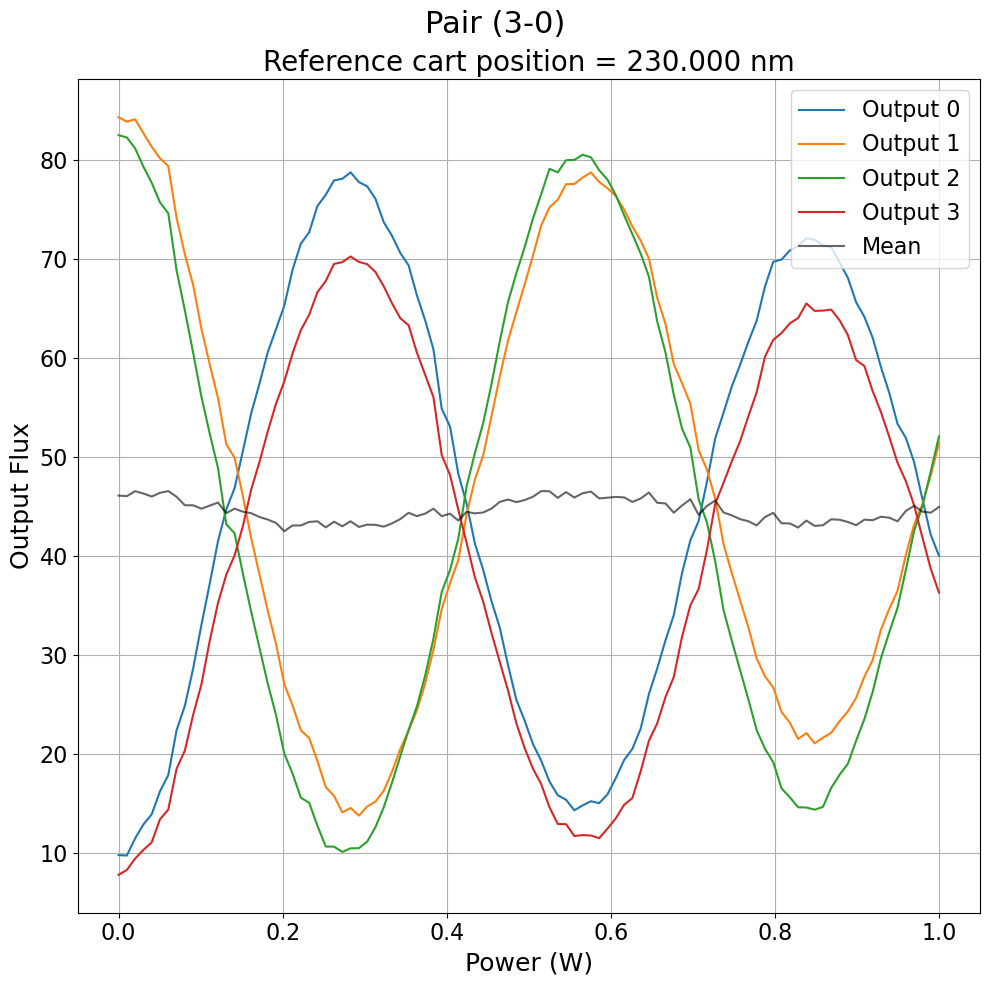

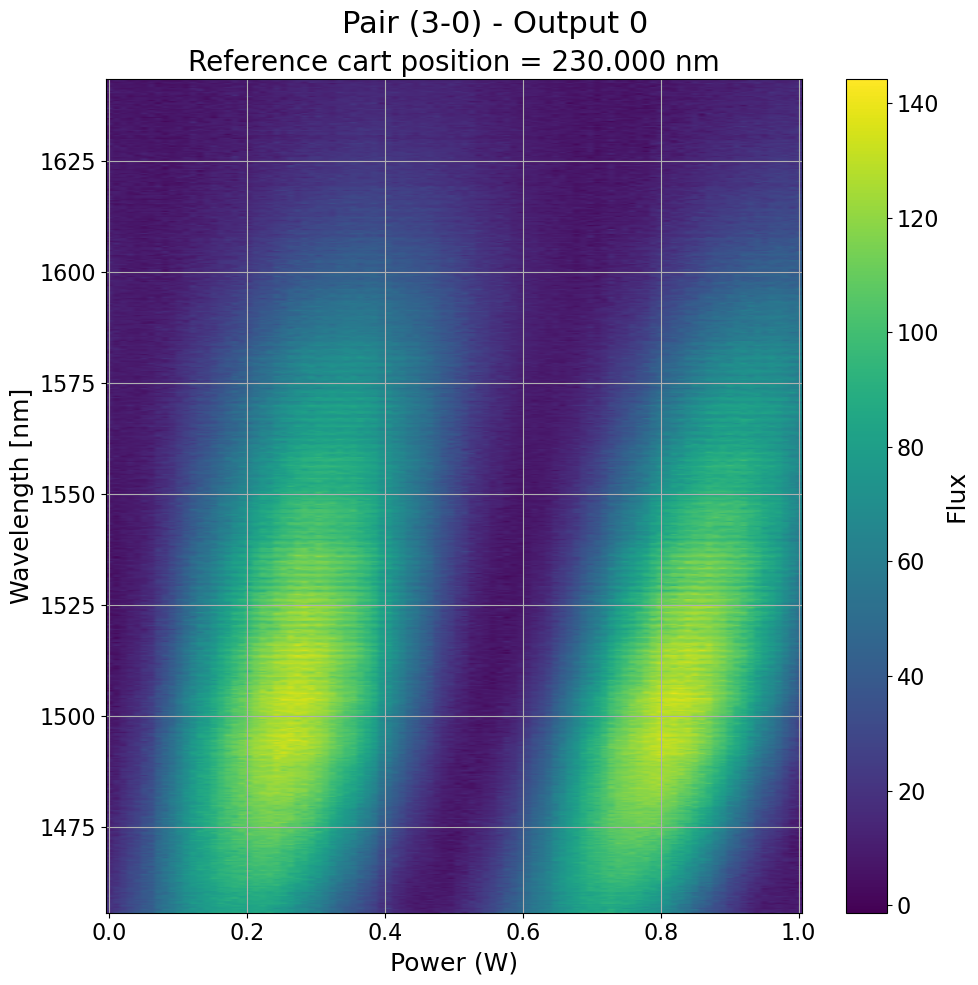

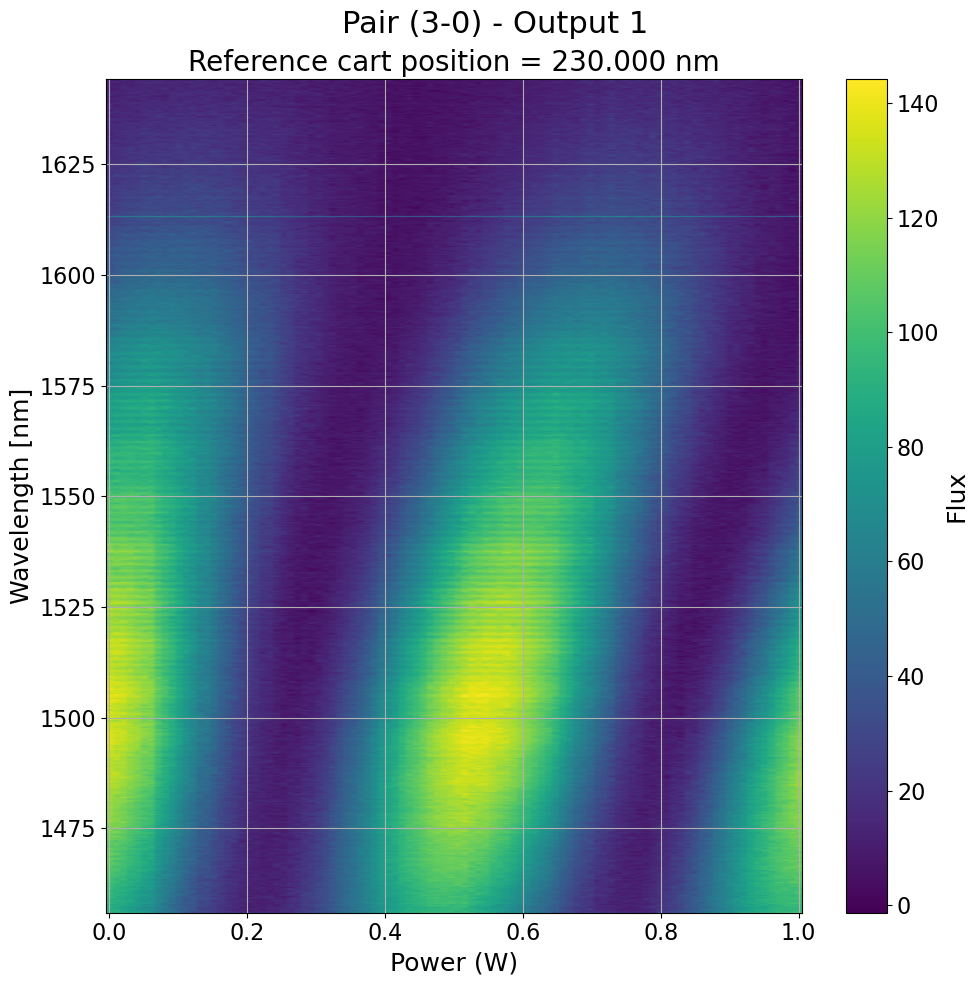

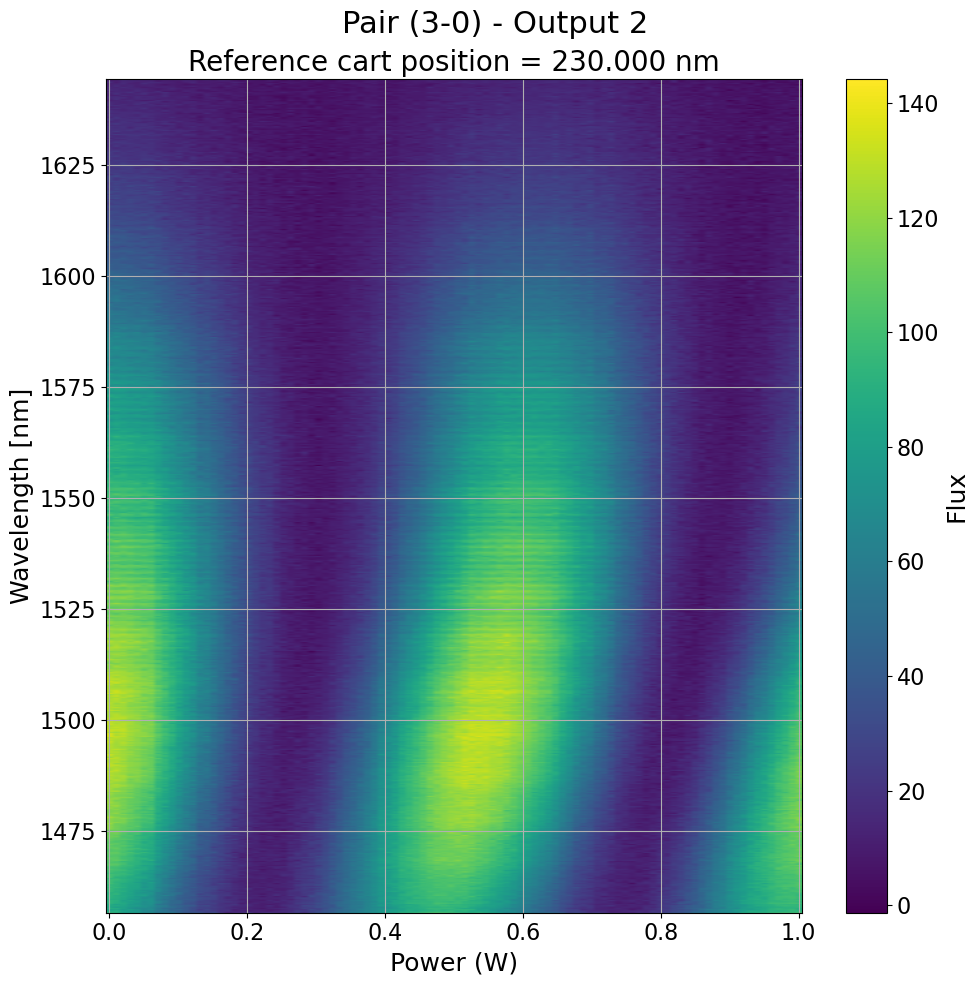

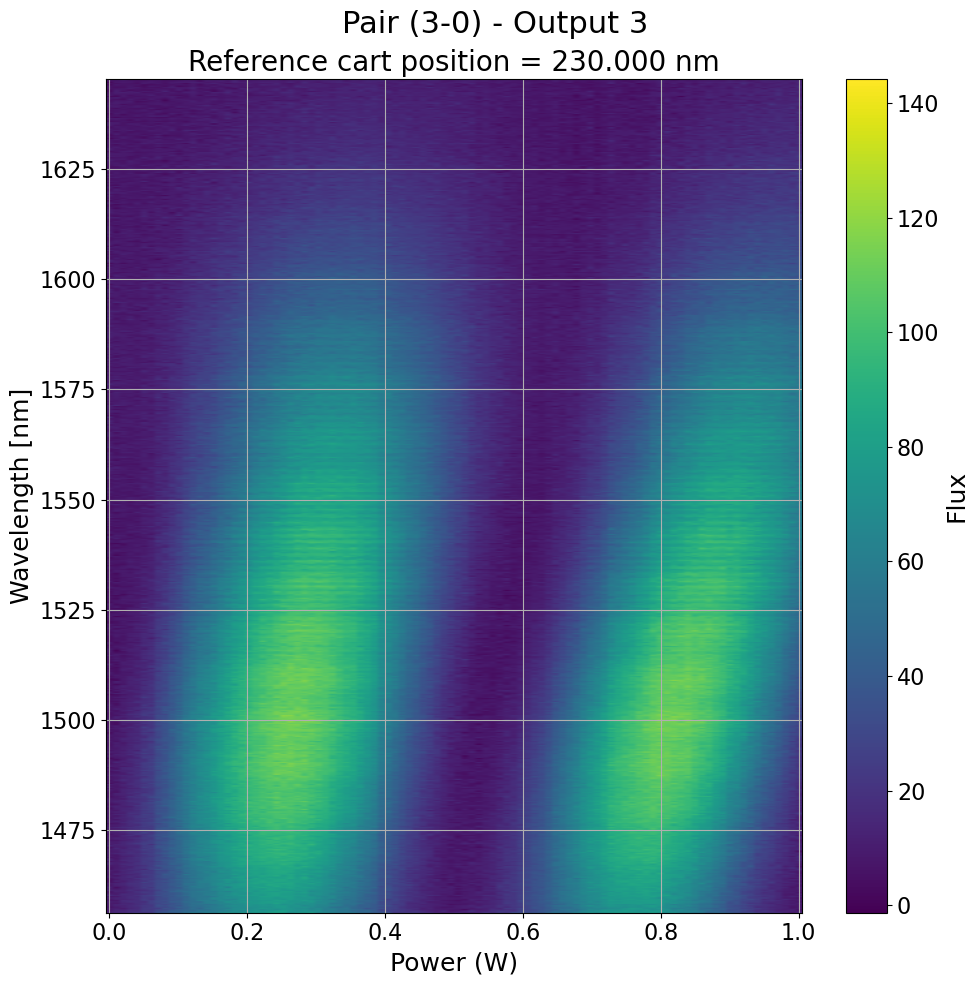

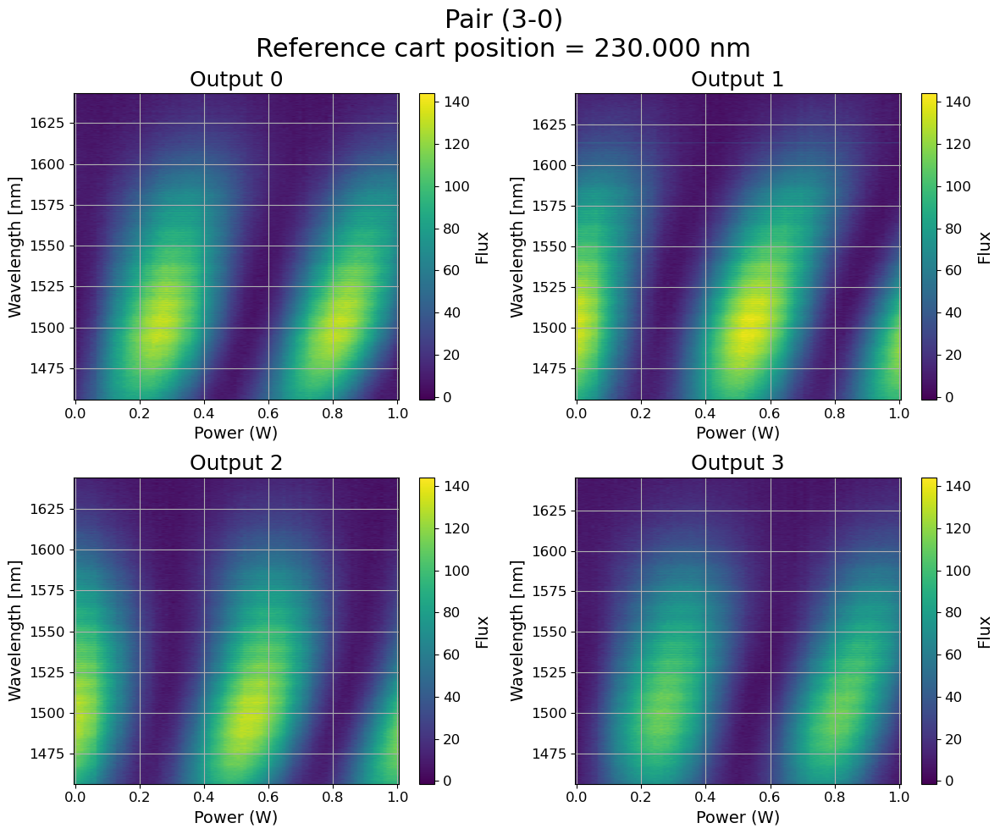

In [77]:
# Plot integrated flux
opd_step = power_ramp30t[1] - power_ramp30t[0]

fig, axs = plot_integrated_flux(
    opd_range=power_ramp30t,
    outs=outs30t,
    n_roi=n_roi,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=power_ramp30t,
    path=path,
    filename_prefix='opd0_topa_scan_pair',
    xlabel = 'Power (W)',
    sec_axis = False
)

_ = plot_spectral_maps_by_output(
    opd_range=power_ramp30t,        # use opd_range20 in the other cell
    spectral_outs=spectral_outs30t, # use spectral_outs20 in the other cell
    spectral_axs=spectral_axs,
    spec_law=spec_law,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=power_ramp30t,   # use piston_range20 in the other cell
    path=path,
    filename_prefix='opd0_topa_scan_spectral_pair',
    xlabel = 'Power (W)',
    sec_axis = False   
)

_ = plot_spectral_maps_grid(
    opd_range=power_ramp30t,          # use opd_range30 in the other cell
    spectral_outs=spectral_outs30t,  # use spectral_outs30 in the other cell
    spectral_axs=spectral_axs,
    spec_law=spec_law,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=power_ramp30t,    # use piston_range30 in the other cell
    path=path,
    filename_prefix='opd0_topa_scan_spectral_pair',
    xlabel = 'Power (W)',
    sec_axis = False
)

## Pair 1-0

In [63]:
ref_cart = 230
dm_pos = max_flux_pos10[0] + lam / 4.
start, end = 0., 1.
nbframes = 10
spec_law = np.load(path / 'spec_cal_coeffs_and_errors.npy')[0]

pair = (1,0)
crop_mode = 'rectangles'
shapes = cam.get_outputs(flux_mode='mean', crop_mode=crop_mode).shape 
n_roi = shapes[0] - 1
spectral_sz = shapes[1]
crop_areas = np.array(phobos.Config().get('cred3.output_rectangles'))
crop_areas = crop_areas[:n_roi]
crop_areas = crop_areas[:,[0,2]] # Got the spectral bounds of each track
spectral_axs = np.array([np.arange(crop_areas[i,0], crop_areas[i,-1]) for i in range(crop_areas.shape[0])])
spectral_axs = np.array([np.polyval(spec_law[i], spectral_axs[i]) for i in range(spectral_axs.shape[0])])

outs10t, spectral_outs10t, max_flux_pos10t, power_ramp10t = scan_topa_white_fringe(start, end, nbframes, ref_cart, dm_pos)
filename = f'opd0_topa_scan_pair_{pair[0]}-{pair[1]}_ref_{int(ref_cart)}-{int(dm_pos)}nm_range_{int(start)}_{int(end)}W.npz'
np.savez(path / filename, 
         data=outs10t, 
         spectral_data=spectral_outs10t, 
         ref_cart=ref_cart, 
         power_ramp=power_ramp10t, 
         )
print('Data saved in', path / filename)

Injection OFF on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
Injection BALANCED on channels [1, 0] (segments [137, 138])


100%|██████████| 100/100 [00:12<00:00,  8.19it/s]


TOPA Max flux for output 3: 0.8787878787878789
TOPA Max flux for output 0: 0.5858585858585859
Data saved in /mnt/disk1/archive/2026-06-30_75b9dd8/4_2T_hypercube/opd0_topa_scan_pair_1-0_ref_230--1807nm_range_0_1W.npz


In [64]:
# set_topa_to_white_fringe(pair, max_flux_pos10t[0], ref_cart, dm_pos)
set_topa_to_white_fringe(pair, 0.88, ref_cart, dm_pos)


Injection OFF on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])
Injection BALANCED on channels [1, 0] (segments [137, 138])


In [65]:
chip.turn_off()

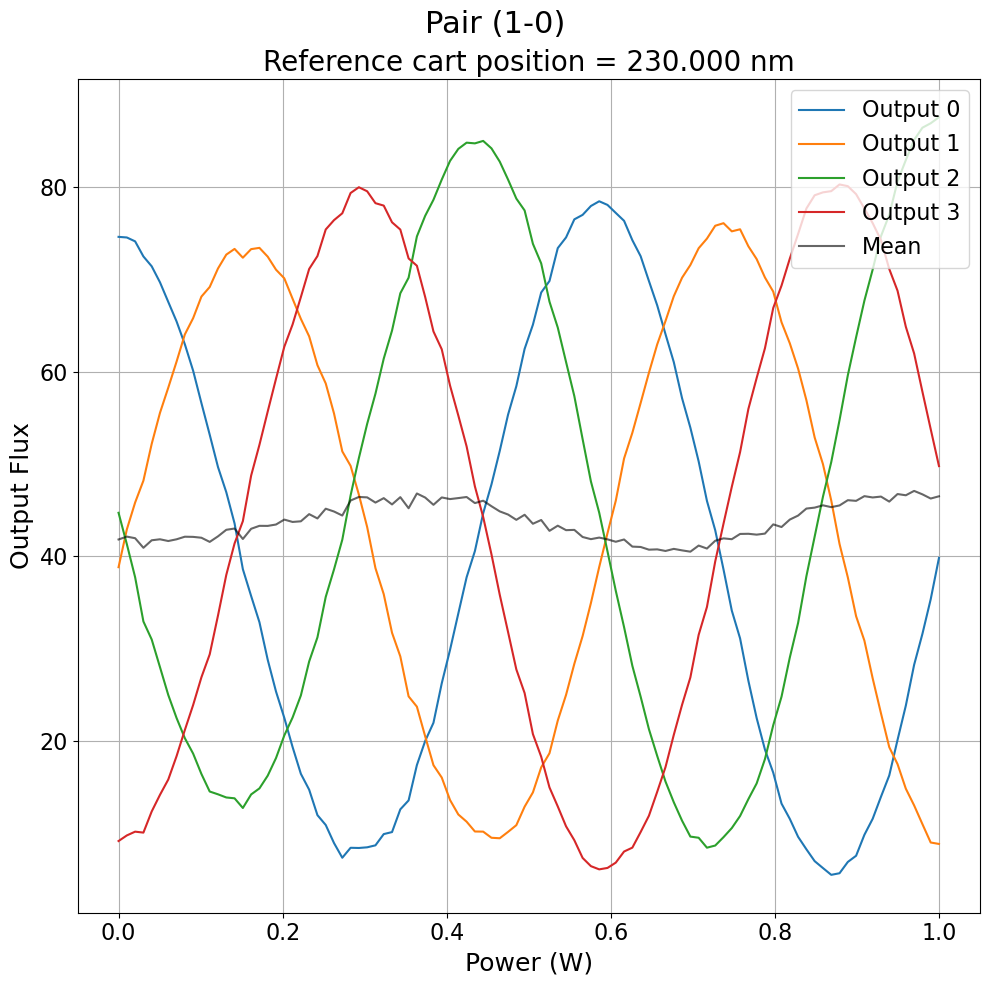

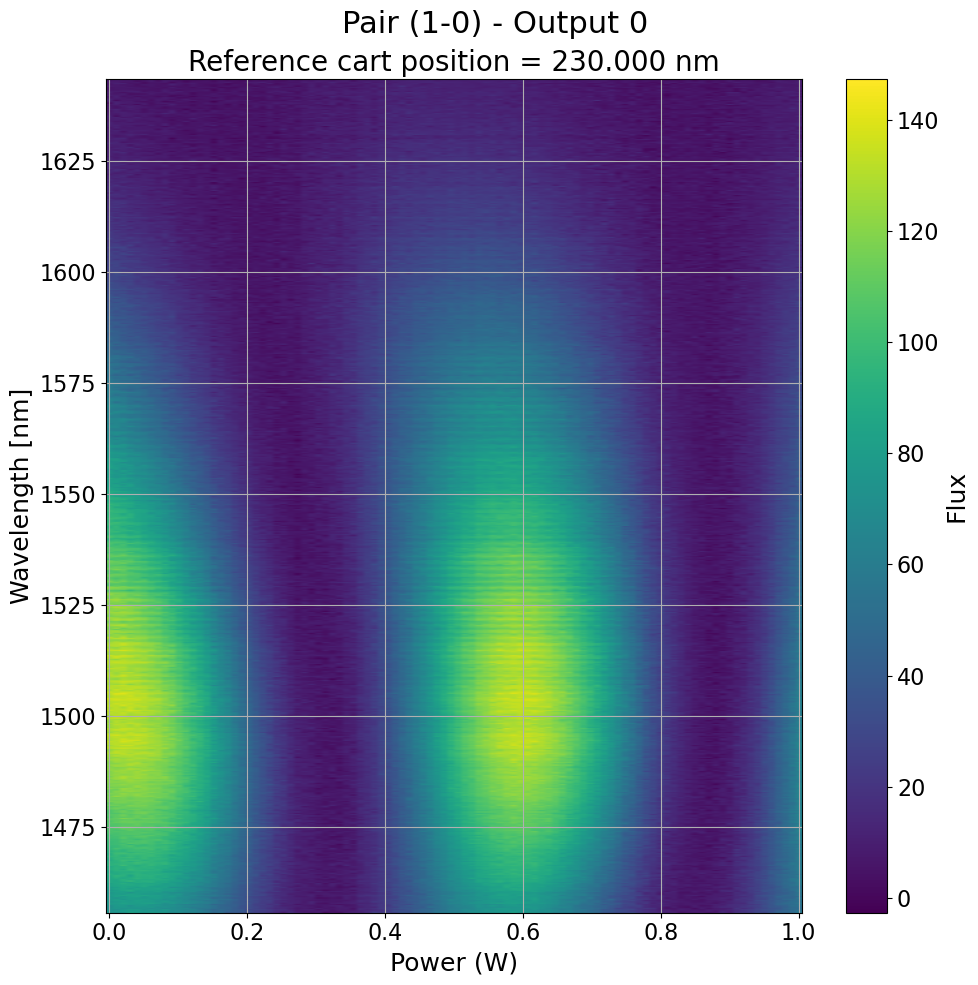

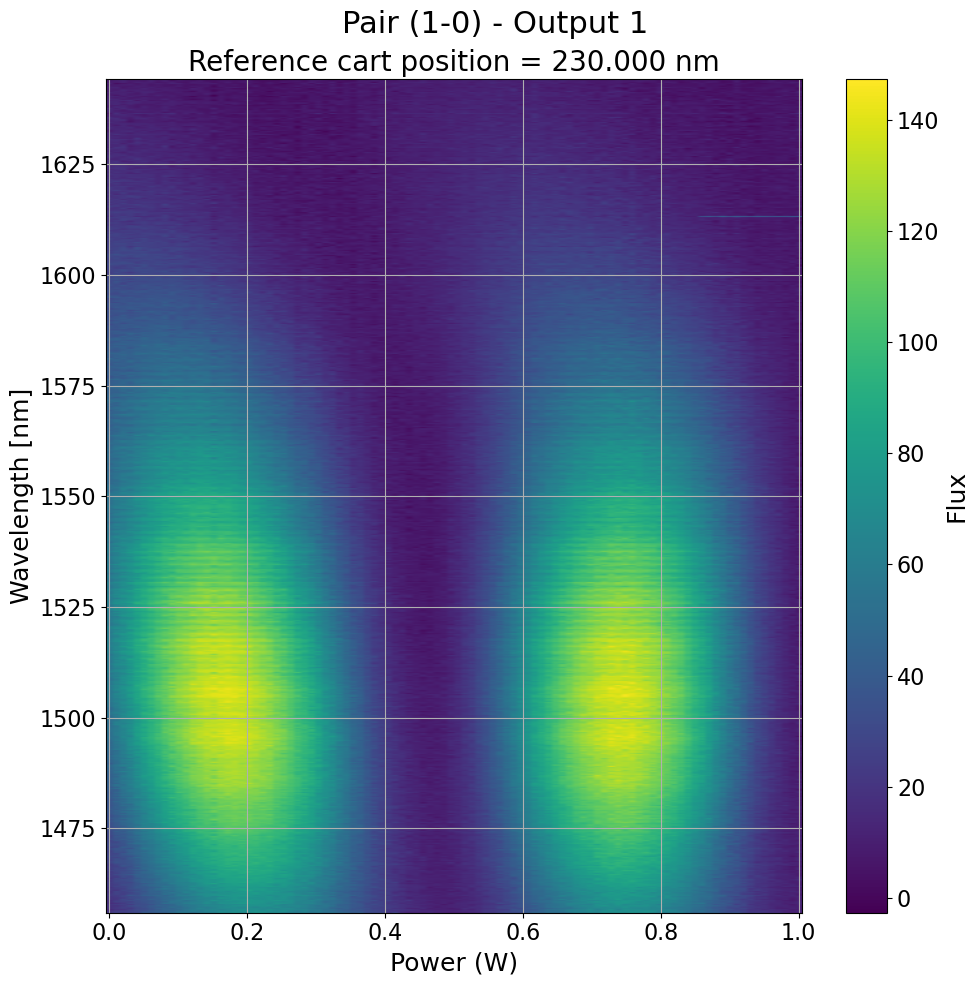

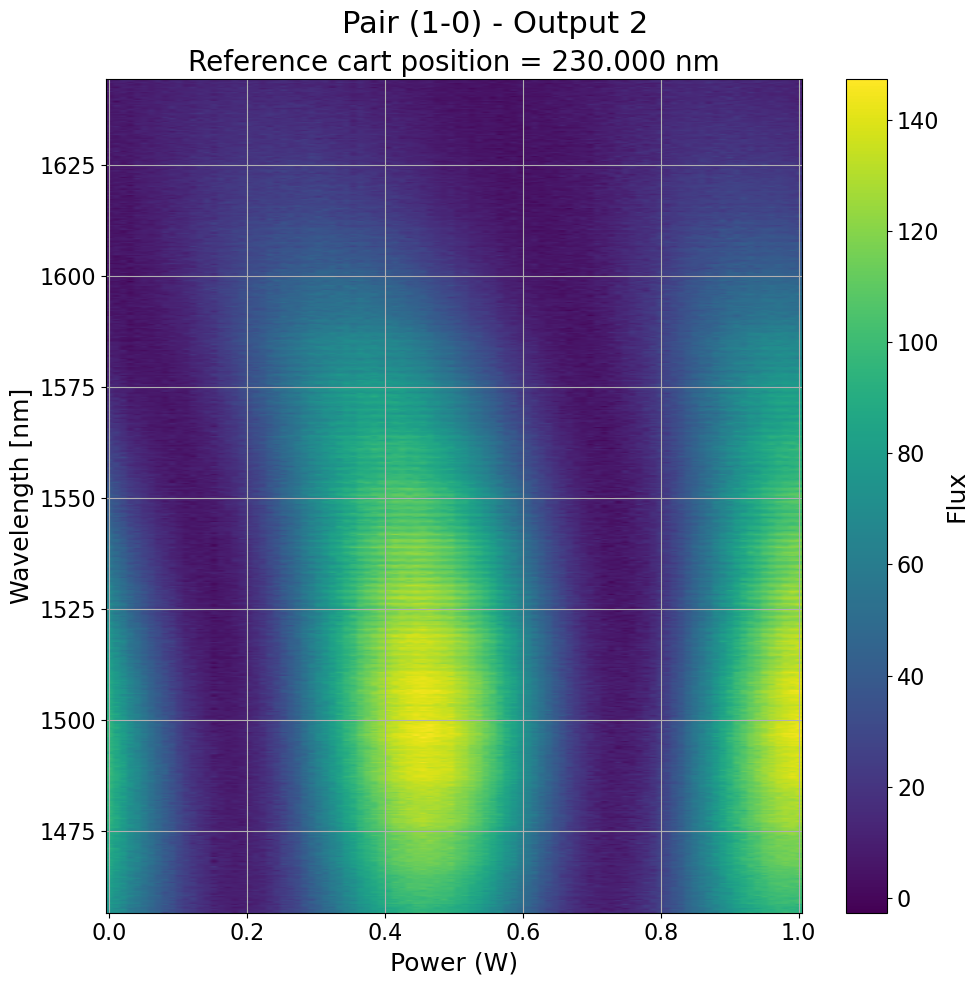

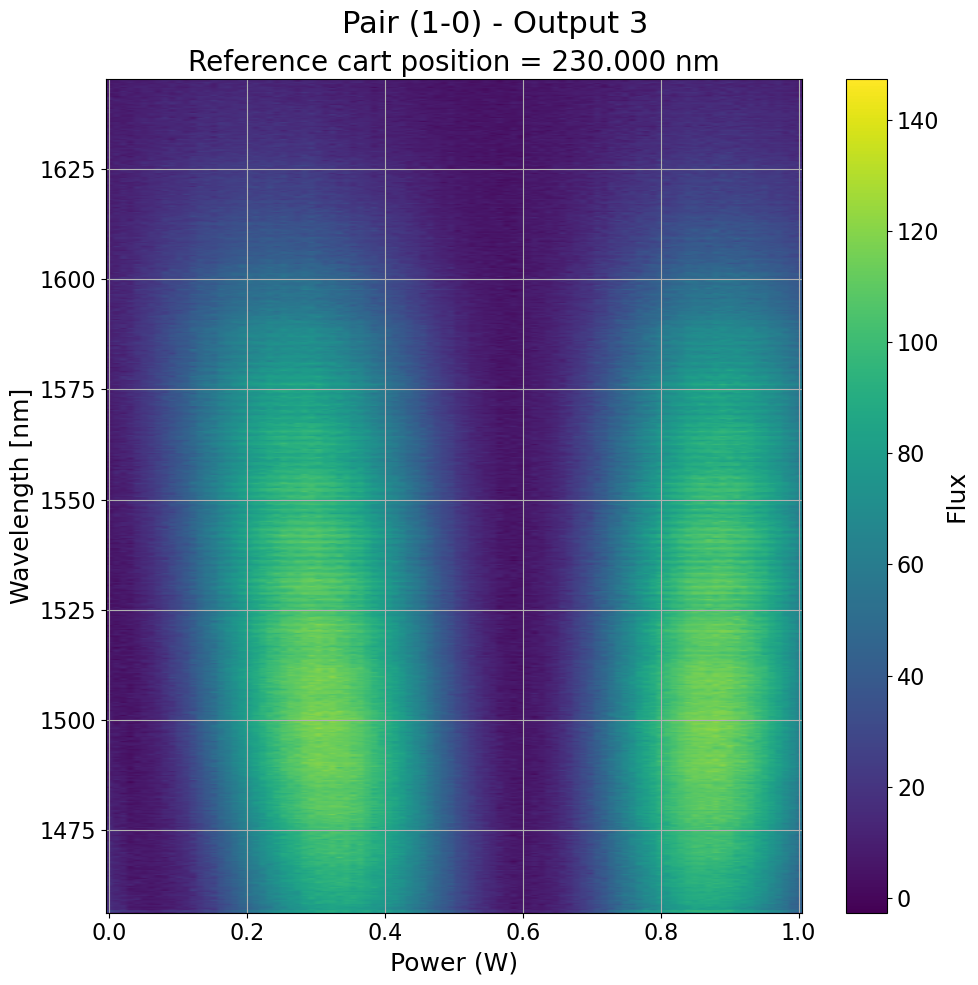

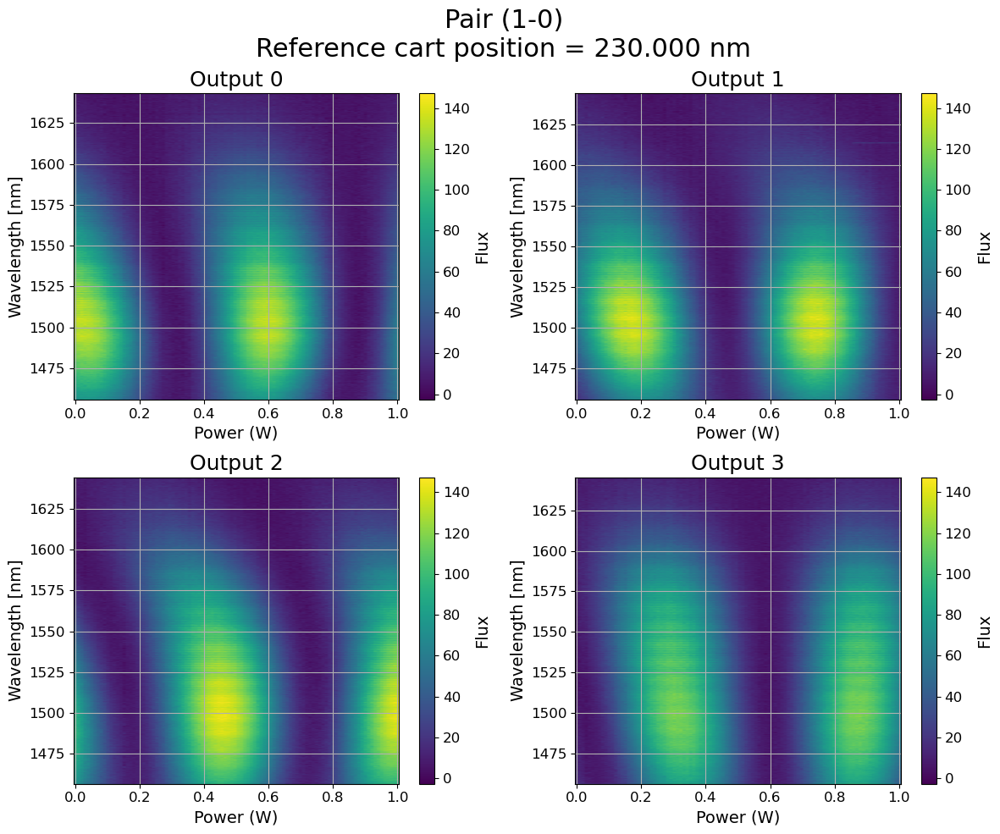

In [66]:
# Plot integrated flux
opd_step = power_ramp10t[1] - power_ramp10t[0]

fig, axs = plot_integrated_flux(
    opd_range=power_ramp10t,
    outs=outs10t,
    n_roi=n_roi,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=power_ramp10t,
    path=path,
    filename_prefix='opd0_topa_scan_pair',
    xlabel = 'Power (W)',
    sec_axis = False
)

_ = plot_spectral_maps_by_output(
    opd_range=power_ramp10t,        # use opd_range20 in the other cell
    spectral_outs=spectral_outs10t, # use spectral_outs20 in the other cell
    spectral_axs=spectral_axs,
    spec_law=spec_law,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=power_ramp10t,   # use piston_range20 in the other cell
    path=path,
    filename_prefix='opd0_topa_scan_spectral_pair',
    xlabel = 'Power (W)',
    sec_axis = False   
)

_ = plot_spectral_maps_grid(
    opd_range=power_ramp10t,          # use opd_range30 in the other cell
    spectral_outs=spectral_outs10t,  # use spectral_outs30 in the other cell
    spectral_axs=spectral_axs,
    spec_law=spec_law,
    pair=pair,
    ref_cart=ref_cart,
    piston_range=power_ramp10t,    # use piston_range30 in the other cell
    path=path,
    filename_prefix='opd0_topa_scan_spectral_pair',
    xlabel = 'Power (W)',
    sec_axis = False
)

# TOPs: Scanning the 3 TOPs

In [60]:
chip.turn_off()

In [ ]:
nsamp = 15
power_range_p1 = np.linspace(0.5, 1., nsamp)
power_range_p2 = np.linspace(0, 0.5, nsamp)
power_range_p3 = np.array([0.])
inj.set_balanced()
ref_tip = [dm[elt].get_tip() for elt in inj_seg]
ref_tilt = [dm[elt].get_tilt() for elt in inj_seg]
nstack = 10
crop_mode = 'rectangles'

ref_cart = 230
dm_pos = [ref_cart, 
          max_flux_pos10[0] + lam / 4., 
          max_flux_pos20[1], 
          max_flux_pos30[0] + lam / 4.]


for i in range(len(inj_seg)):
    dm[inj_seg[i]].set_ptt(dm_pos[i], ref_tip[i], ref_tilt[i])
img = cam.get_outputs(stack=nstack, crop_mode=crop_mode)

datacube = []

for p1 in tqdm(power_range_p1): # iterate over inj_seg[1] = 137
    temp1 = []
    for p2 in power_range_p2: # iterate over inj_seg[2] = 136
        temp2 = []
        for p3 in power_range_p3: # iterate over inj_seg[3] = 135
            phases = np.array([0., p1, p2, p3])
            chip.set_powers(phases)
            img = cam.get_outputs(stack=nstack, crop_mode=crop_mode)
            temp2.append(img)
        temp1.append(temp2)
    datacube.append(temp1)

datacube = np.array(datacube)
chip.turn_off()
np.savez(path / f'topa_scan_kernel_4x4_datacube_refcart_{ref_cart}_{int(np.around(dm_pos[1]))}_{int(np.around(dm_pos[2]))}_{int(np.around(dm_pos[3]))}_start_{int(start)}_end_{int(end)}.npz', data=datacube, power_range_p1=power_range_p1, power_range_p2=power_range_p2, power_range_p3=power_range_p3)


Injection BALANCED on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])


100%|██████████| 30/30 [01:37<00:00,  3.26s/it]


# The end

In [78]:
print('Path is', path)

inj.zero()

Path is /mnt/disk1/archive/2026-06-30_75b9dd8/4_2T_hypercube
Injection ZERO on channels [0, 1, 2, 3] (segments [138, 137, 136, 135])


In [80]:
phobos.XPOW().turn_off()